In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

PROJECT_PATH = Path("..")
PROCESSED_PATH = PROJECT_PATH / "data" / "processed"

print("Processed data path:", PROCESSED_PATH)

Processed data path: ..\data\processed


In [2]:
transactions = pd.read_csv(
    PROCESSED_PATH/"fact_transaction_clean.csv"
)
print("Transaction shape",transactions.shape)

print("\nColumns:")
print(transactions.columns.tolist())

display(transactions.head())

Transaction shape (1498353, 14)

Columns:
['txn_id', 'card_id', 'customer_id', 'merchant_id', 'device_id', 'txn_ts', 'amount', 'channel', 'category', 'merchant_city', 'merchant_country', 'ip_country', 'auth_result', 'customer_home_city']


,txn_id,card_id,customer_id,merchant_id,device_id,txn_ts,amount,channel,category,merchant_city,merchant_country,ip_country,auth_result,customer_home_city
0,1,10359,6694,554,16884,2025-02-10 06:36:14,"2,253.14",E_COMMERCE,Fuel,Chandigarh,India,India,APPROVED,Ahmedabad
1,2,20959,9196,1643,1313,2025-12-07 15:12:17,"6,113.61",POS,Clothing,Kolkata,India,India,APPROVED,Chandigarh
2,3,3769,12095,500,13865,2025-08-24 23:11:07,"1,019.19",E_COMMERCE,Online Services,Mumbai,India,USA,APPROVED,Delhi
3,4,3632,12480,724,32906,2025-12-26 15:15:35,"1,447.45",E_COMMERCE,Entertainment,Chandigarh,India,India,APPROVED,Chennai
4,5,11165,2880,26,29838,2025-03-04 04:26:12,"1,534.02",E_COMMERCE,Entertainment,Ahmedabad,India,India,APPROVED,Jaipur


In [3]:
customers = pd.read_csv(
    PROCESSED_PATH / "dim_customer.csv"
)

cards = pd.read_csv(
    PROCESSED_PATH / "dim_card.csv"
)

merchants = pd.read_csv(
    PROCESSED_PATH / "dim_merchant.csv"
)

devices = pd.read_csv(
    PROCESSED_PATH / "dim_device.csv"
)

chargebacks = pd.read_csv(
    PROCESSED_PATH / "fact_chargeback.csv"
)

print("Customers:", customers.shape)
print("Cards:", cards.shape)
print("Merchants:", merchants.shape)
print("Devices:", devices.shape)
print("Chargebacks:", chargebacks.shape)

Customers: (20000, 10)
Cards: (30000, 6)
Merchants: (2000, 6)
Devices: (35001, 3)
Chargebacks: (10500, 5)


In [4]:
transactions["txn_ts"] = pd.to_datetime(
    transactions["txn_ts"],
    errors="coerce",
    format="mixed"
)

print("Invalid timestamps:",
      transactions["txn_ts"].isna().sum())

print(
    "Transaction period:",
    transactions["txn_ts"].min(),
    "to",
    transactions["txn_ts"].max()
)

Invalid timestamps: 0
Transaction period: 2025-01-01 00:00:03 to 2025-12-31 23:59:35


In [5]:
print("=" * 60)
print("TRANSACTION BASELINE")
print("=" * 60)

print("Total transactions:", len(transactions))

print(
    "Total transaction value: ₹",
    f"{transactions['amount'].sum():,.2f}"
)

print(
    "Average transaction: ₹",
    f"{transactions['amount'].mean():,.2f}"
)

print(
    "Median transaction: ₹",
    f"{transactions['amount'].median():,.2f}"
)

print(
    "Minimum transaction: ₹",
    f"{transactions['amount'].min():,.2f}"
)

print(
    "Maximum transaction: ₹",
    f"{transactions['amount'].max():,.2f}"
)

TRANSACTION BASELINE
Total transactions: 1498353
Total transaction value: ₹ 3,762,810,623.99
Average transaction: ₹ 2,511.30
Median transaction: ₹ 1,495.02
Minimum transaction: ₹ 1.07
Maximum transaction: ₹ 250,000.00


In [9]:
# Create fraud label from confirmed chargebacks

fraud_txn_ids = set(
    chargebacks.loc[
        chargebacks["confirmed_fraud_flag"] == 1,
        "txn_id"
    ]
)

transactions["is_fraud"] = transactions["txn_id"].isin(
    fraud_txn_ids
).astype(int)

print("=" * 60)
print("FRAUD LABEL BASELINE")
print("=" * 60)

print("Confirmed fraud transactions:", transactions["is_fraud"].sum())

print(
    "Non-fraud transactions:",
    (transactions["is_fraud"] == 0).sum()
)

print(
    "Fraud rate:",
    f"{transactions['is_fraud'].mean() * 100:.4f}%"
)

FRAUD LABEL BASELINE
Confirmed fraud transactions: 10488
Non-fraud transactions: 1487865
Fraud rate: 0.7000%


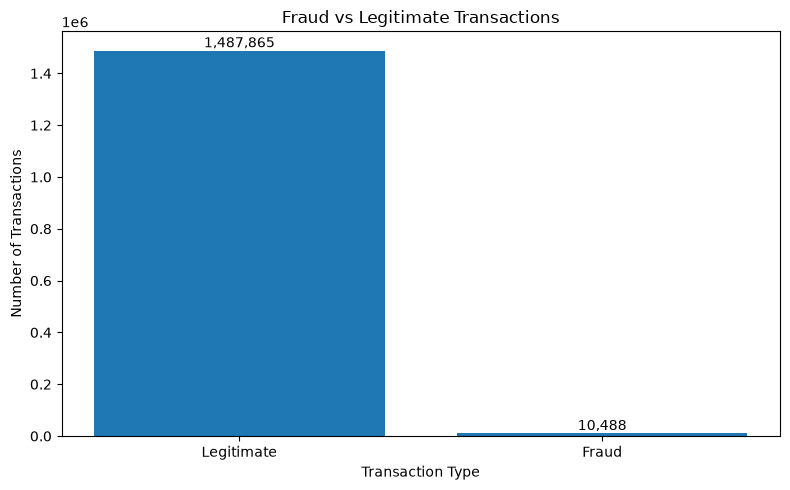

In [34]:
# Visualization 1: Fraud vs non-fraud transactions

fraud_counts = (
    transactions["is_fraud"]
    .map({0: "Legitimate", 1: "Fraud"})
    .value_counts()
)

plt.figure(figsize=(8, 5))

plt.bar(
    fraud_counts.index,
    fraud_counts.values
)

plt.title("Fraud vs Legitimate Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")

for i, value in enumerate(fraud_counts.values):
    plt.text(
        i,
        value,
        f"{value:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [10]:
fraud_transactions = transactions[
    transactions["is_fraud"] == 1
].copy()

legitimate_transactions = transactions[
    transactions["is_fraud"] == 0
].copy()

total_fraud_value = fraud_transactions["amount"].sum()
total_legitimate_value = legitimate_transactions["amount"].sum()

print("=" * 60)
print("FRAUD VALUE BASELINE")
print("=" * 60)

print(
    "Fraud transactions:",
    f"{len(fraud_transactions):,}"
)

print(
    "Fraud transaction value: ₹",
    f"{total_fraud_value:,.2f}"
)

print(
    "Legitimate transaction value: ₹",
    f"{total_legitimate_value:,.2f}"
)

print(
    "Fraud value as % of transaction value:",
    f"{total_fraud_value / transactions['amount'].sum() * 100:.4f}%"
)

FRAUD VALUE BASELINE
Fraud transactions: 10,488
Fraud transaction value: ₹ 95,197,860.34
Legitimate transaction value: ₹ 3,667,612,763.65
Fraud value as % of transaction value: 2.5300%


In [11]:
chargeback_loss = chargebacks["loss_amount"].sum()
chargeback_recovery = chargebacks["recovered_amount"].sum()
chargeback_net_loss = (
    chargeback_loss - chargeback_recovery
)

print("=" * 60)
print("CHARGEBACK LOSS BASELINE")
print("=" * 60)

print(
    "Gross chargeback loss: ₹",
    f"{chargeback_loss:,.2f}"
)

print(
    "Recovered amount: ₹",
    f"{chargeback_recovery:,.2f}"
)

print(
    "Net chargeback loss: ₹",
    f"{chargeback_net_loss:,.2f}"
)

CHARGEBACK LOSS BASELINE
Gross chargeback loss: ₹ 95,285,937.42
Recovered amount: ₹ 26,506,448.86
Net chargeback loss: ₹ 68,779,488.56


In [12]:
channel_baseline = (
    transactions
    .groupby("channel")
    .agg(
        transactions = ("txn_id","count"),
        transactions_value = ("amount","sum"),
        fraud_transactions = ("is_fraud","sum"),
        fraud_value = ("amount",lambda x: 
                       x[transactions.loc[x.index,"is_fraud"] == 1].sum())
    )
    .reset_index()
)

channel_baseline["fraud_rate_pct"] = (
    channel_baseline["fraud_transactions"]
    / channel_baseline["transactions"]
    *100
)


channel_baseline["fraud_value_pct"] = (
    channel_baseline["fraud_value"]
    / channel_baseline["transactions_value"]
    * 100
)

channel_baseline = channel_baseline.sort_values(
    "fraud_value",
    ascending=False
)

display(channel_baseline)

,channel,transactions,transactions_value,fraud_transactions,fraud_value,fraud_rate_pct,fraud_value_pct
2,E_COMMERCE,572928,"1,475,482,560.90",7705,"79,988,283.24",1.34,5.42
3,POS,626875,"1,547,832,077.78",1893,"10,304,227.08",0.30,0.67
1,CONTACTLESS,178820,"441,781,515.45",515,"2,828,225.78",0.29,0.64
0,ATM,119730,"297,714,469.86",375,"2,077,124.24",0.31,0.70


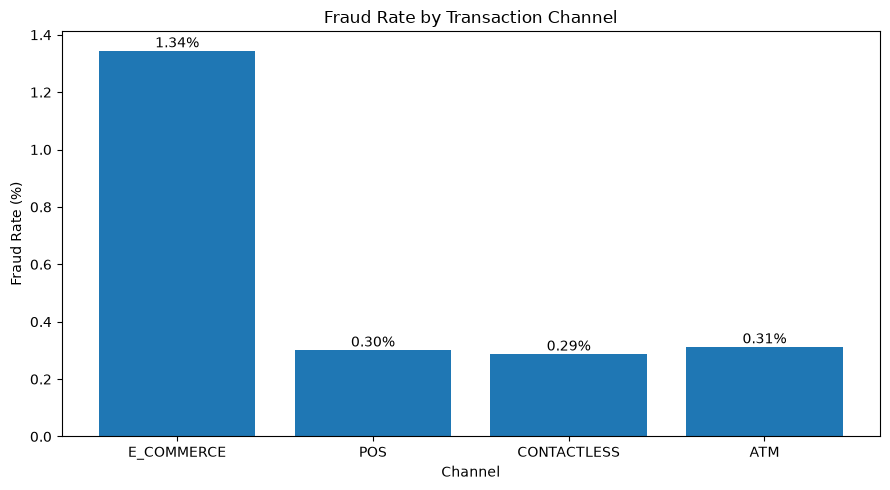

In [36]:
# Visualization 2: Fraud rate by channel

plt.figure(figsize=(9, 5))

plt.bar(
    channel_baseline["channel"],
    channel_baseline["fraud_rate_pct"]
)

plt.title("Fraud Rate by Transaction Channel")
plt.xlabel("Channel")
plt.ylabel("Fraud Rate (%)")

for i, value in enumerate(channel_baseline["fraud_rate_pct"]):
    plt.text(
        i,
        value,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [13]:
category_baseline = (
    transactions
    .groupby("category")
    .agg(
        transactions=("txn_id", "count"),
        transaction_value=("amount", "sum"),
        fraud_transactions=("is_fraud", "sum"),
        fraud_value=("amount", lambda x:
                     x[transactions.loc[x.index, "is_fraud"] == 1].sum())
    )
    .reset_index()
)

category_baseline["fraud_rate_pct"] = (
    category_baseline["fraud_transactions"]
    / category_baseline["transactions"]
    * 100
)

category_baseline["fraud_value_pct"] = (
    category_baseline["fraud_value"]
    / category_baseline["transaction_value"]
    * 100
)

category_baseline = category_baseline.sort_values(
    "fraud_value",
    ascending=False
)

display(category_baseline)

,category,transactions,transaction_value,fraud_transactions,fraud_value,fraud_rate_pct,fraud_value_pct
2,Electronics,125175,"340,770,122.24",1820,"37,195,582.66",1.45,10.92
5,Gift Cards,137426,"371,920,430.24",1863,"34,719,369.94",1.36,9.34
10,Travel,161689,"397,549,294.32",895,"3,010,383.57",0.55,0.76
0,Clothing,130096,"322,537,161.54",733,"2,720,082.57",0.56,0.84
7,Healthcare,135453,"333,508,429.92",748,"2,653,326.91",0.55,0.80
6,Grocery,137227,"338,530,860.77",732,"2,628,546.93",0.53,0.78
3,Entertainment,155294,"382,416,456.96",827,"2,626,975.45",0.53,0.69
4,Fuel,135610,"335,324,132.03",753,"2,498,938.23",0.56,0.75
9,Online Services,129502,"319,275,249.67",728,"2,482,512.76",0.56,0.78
1,Dining,127091,"315,209,970.16",675,"2,403,123.78",0.53,0.76


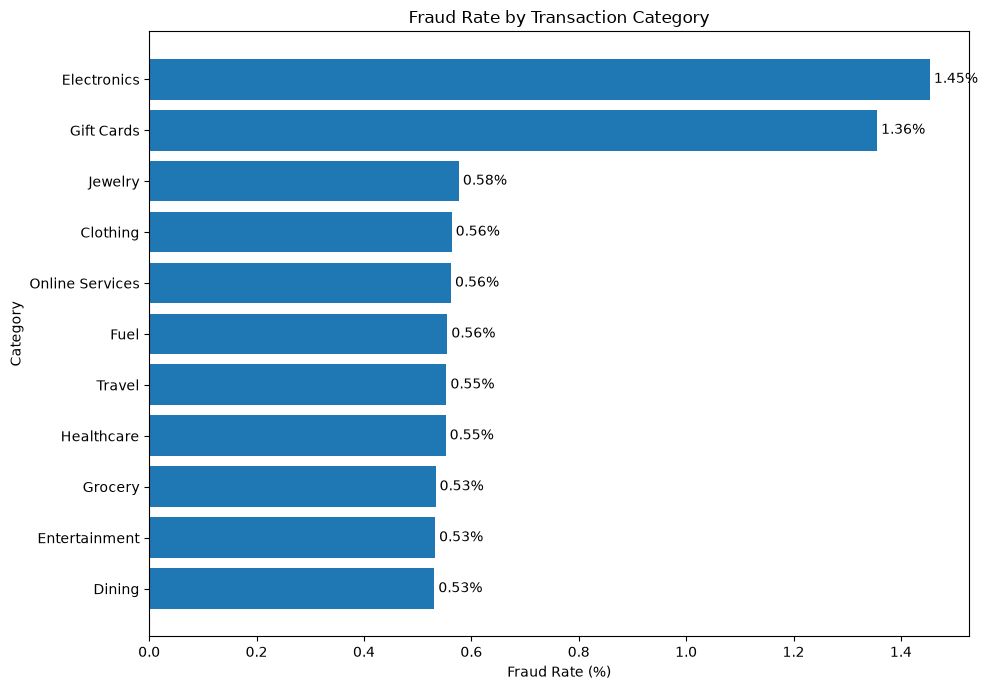

In [39]:
# Visualization 4: Fraud rate by category

category_plot = category_baseline.sort_values(
    "fraud_rate_pct",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    category_plot["category"],
    category_plot["fraud_rate_pct"]
)

plt.title("Fraud Rate by Transaction Category")
plt.xlabel("Fraud Rate (%)")
plt.ylabel("Category")

for i, value in enumerate(category_plot["fraud_rate_pct"]):
    plt.text(
        value,
        i,
        f" {value:.2f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

In [14]:
transactions["txn_hour"] = transactions["txn_ts"].dt.hour

hour_baseline = (
    transactions
    .groupby("txn_hour")
    .agg(
        transactions=("txn_id", "count"),
        transaction_value=("amount", "sum"),
        fraud_transactions=("is_fraud", "sum"),
        fraud_value=("amount", lambda x:
                     x[transactions.loc[x.index, "is_fraud"] == 1].sum())
    )
    .reset_index()
)

hour_baseline["fraud_rate_pct"] = (
    hour_baseline["fraud_transactions"]
    / hour_baseline["transactions"]
    * 100
)

hour_baseline["fraud_value_pct"] = (
    hour_baseline["fraud_value"]
    / hour_baseline["transaction_value"]
    * 100
)

display(hour_baseline)

,txn_hour,transactions,transaction_value,fraud_transactions,fraud_value,fraud_rate_pct,fraud_value_pct
0,0,62236,"155,803,855.46",443,"4,276,731.20",0.71,2.74
1,1,62681,"156,996,856.77",464,"3,995,239.40",0.74,2.54
2,2,62269,"155,779,838.10",420,"3,920,812.83",0.67,2.52
3,3,62467,"158,779,353.16",454,"4,600,381.22",0.73,2.90
4,4,62610,"158,798,498.46",442,"3,636,133.29",0.71,2.29
5,5,62741,"159,280,420.69",463,"4,444,315.45",0.74,2.79
6,6,62645,"157,328,975.52",447,"4,380,906.65",0.71,2.78
7,7,62427,"156,997,117.88",456,"4,378,256.38",0.73,2.79
8,8,62593,"157,272,026.21",422,"4,465,849.02",0.67,2.84
9,9,62734,"158,136,033.04",425,"3,497,551.97",0.68,2.21


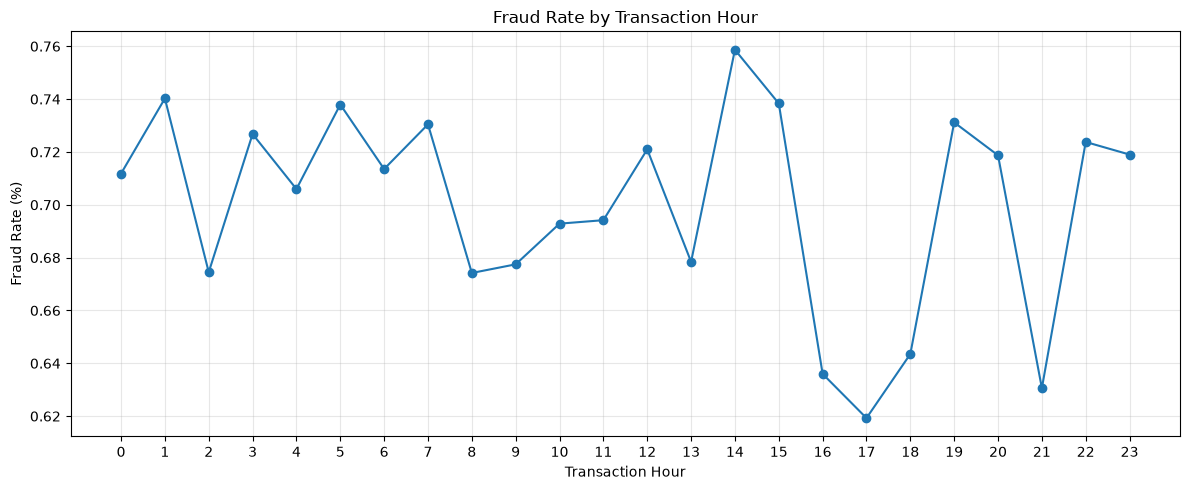

In [40]:
# Visualization 5: Fraud rate by transaction hour

plt.figure(figsize=(12, 5))

plt.plot(
    hour_baseline["txn_hour"],
    hour_baseline["fraud_rate_pct"],
    marker="o"
)

plt.title("Fraud Rate by Transaction Hour")
plt.xlabel("Transaction Hour")
plt.ylabel("Fraud Rate (%)")

plt.xticks(range(0, 24))

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
city_baseline = (
    transactions
    .groupby("merchant_city")
    .agg(
        transactions=("txn_id", "count"),
        transaction_value=("amount", "sum"),
        fraud_transactions=("is_fraud", "sum"),
        fraud_value=("amount", lambda x:
                     x[transactions.loc[x.index, "is_fraud"] == 1].sum())
    )
    .reset_index()
)

city_baseline["fraud_rate_pct"] = (
    city_baseline["fraud_transactions"]
    / city_baseline["transactions"]
    * 100
)

city_baseline["fraud_value_pct"] = (
    city_baseline["fraud_value"]
    / city_baseline["transaction_value"]
    * 100
)

city_baseline = city_baseline.sort_values(
    "fraud_value",
    ascending=False
)

display(city_baseline)

,merchant_city,transactions,transaction_value,fraud_transactions,fraud_value,fraud_rate_pct,fraud_value_pct
14,Surat,104464,"262,279,099.70",752,"7,562,285.87",0.72,2.88
2,Bengaluru,108360,"274,595,753.88",713,"7,388,995.12",0.66,2.69
7,Indore,98902,"249,153,955.72",747,"7,033,164.78",0.76,2.82
1,Bangalore,103096,"257,568,878.83",714,"6,742,708.35",0.69,2.62
10,Lucknow,102813,"257,624,729.29",704,"6,435,453.36",0.68,2.50
5,Delhi,109846,"275,031,315.38",752,"6,320,287.61",0.68,2.30
13,Pune,109681,"275,007,236.71",787,"6,299,414.01",0.72,2.29
8,Jaipur,94491,"238,314,902.76",684,"6,239,523.11",0.72,2.62
12,Nagpur,94132,"236,627,999.03",627,"6,155,993.46",0.67,2.60
3,Chandigarh,94729,"238,879,086.53",693,"6,136,667.03",0.73,2.57


In [16]:
customer_city_baseline = (
    transactions
    .groupby("customer_home_city")
    .agg(
        transactions=("txn_id", "count"),
        transaction_value=("amount", "sum"),
        fraud_transactions=("is_fraud", "sum"),
        fraud_value=("amount", lambda x:
                     x[transactions.loc[x.index, "is_fraud"] == 1].sum())
    )
    .reset_index()
)

customer_city_baseline["fraud_rate_pct"] = (
    customer_city_baseline["fraud_transactions"]
    / customer_city_baseline["transactions"]
    * 100
)

customer_city_baseline["fraud_value_pct"] = (
    customer_city_baseline["fraud_value"]
    / customer_city_baseline["transaction_value"]
    * 100
)

customer_city_baseline = customer_city_baseline.sort_values(
    "fraud_value",
    ascending=False
)

display(customer_city_baseline)

,customer_home_city,transactions,transaction_value,fraud_transactions,fraud_value,fraud_rate_pct,fraud_value_pct
1,Bengaluru,195158,"491,734,572.14",1329,"12,355,360.31",0.68,2.51
4,Delhi,109157,"275,602,249.28",752,"7,047,969.50",0.69,2.56
5,Hyderabad,98897,"247,678,623.94",771,"6,999,994.87",0.78,2.83
8,Kolkata,101065,"254,398,878.87",743,"6,835,963.25",0.74,2.69
11,Nagpur,97078,"244,603,358.99",675,"6,708,235.25",0.70,2.74
0,Ahmedabad,92566,"231,491,417.42",639,"6,489,529.53",0.69,2.80
9,Lucknow,103599,"259,209,076.25",715,"6,434,637.73",0.69,2.48
7,Jaipur,99329,"248,265,540.85",681,"6,368,404.90",0.69,2.57
6,Indore,99481,"249,798,145.49",702,"6,355,502.56",0.71,2.54
12,Pune,102476,"258,212,352.93",676,"6,279,391.20",0.66,2.43


In [17]:
print(cards.columns.tolist())
display(cards.head())

['card_id', 'customer_id', 'card_type', 'issue_date', 'credit_limit', 'status']


,card_id,customer_id,card_type,issue_date,credit_limit,status
0,1,14090,CREDIT,2023-11-28,50000,ACTIVE
1,2,15385,PREMIUM,2024-09-01,50000,ACTIVE
2,3,10838,CREDIT,2024-07-02,100000,ACTIVE
3,4,12820,CREDIT,2024-06-07,100000,ACTIVE
4,5,13035,CREDIT,2024-04-24,500000,ACTIVE


In [18]:
# Cell 14: Calculate card age

cards["issue_date"] = pd.to_datetime(
    cards["issue_date"],
    errors="coerce"
)

# Calculate card age relative to the start of the transaction period
analysis_start_date = transactions["txn_ts"].min().normalize()

cards["card_age_days"] = (
    analysis_start_date - cards["issue_date"]
).dt.days

cards["card_age_months"] = (
    cards["card_age_days"] / 30.44
).round(1)

print("Analysis start date:", analysis_start_date)
print("\nCard age summary:")
display(
    cards["card_age_days"].describe()
)

Analysis start date: 2025-01-01 00:00:00

Card age summary:


count   30,000.00
mean       447.84
std        259.77
min          0.00
25%        221.00
50%        448.00
75%        671.00
max        899.00
Name: card_age_days, dtype: float64

In [19]:
# Cell 15: Inspect card age ranges

print("Cards with negative age:", (cards["card_age_days"] < 0).sum())
print("Cards with missing age:", cards["card_age_days"].isna().sum())

display(
    cards[
        ["card_id", "issue_date", "card_age_days", "card_age_months"]
    ].head(10)
)

Cards with negative age: 0
Cards with missing age: 0


,card_id,issue_date,card_age_days,card_age_months
0,1,2023-11-28,400,13.10
1,2,2024-09-01,122,4.00
2,3,2024-07-02,183,6.00
3,4,2024-06-07,208,6.80
4,5,2024-04-24,252,8.30
5,6,2022-08-17,868,28.50
6,7,2024-11-20,42,1.40
7,8,2022-08-19,866,28.40
8,9,2023-11-06,422,13.90
9,10,2023-09-14,475,15.60


In [20]:
# Cell 16: Create card age bands

cards["card_age_band"] = pd.cut(
    cards["card_age_days"],
    bins=[-1, 30, 90, 180, 365, 730, float("inf")],
    labels=[
        "0-30 days",
        "31-90 days",
        "91-180 days",
        "181-365 days",
        "1-2 years",
        "2+ years"
    ]
)

display(
    cards["card_age_band"]
    .value_counts()
    .sort_index()
)

card_age_band
0-30 days        1082
31-90 days       2002
91-180 days      3046
181-365 days     6098
1-2 years       12276
2+ years         5496
Name: count, dtype: int64

In [21]:
# Cell 17: Add card age information to transactions

transactions = transactions.merge(
    cards[
        [
            "card_id",
            "card_type",
            "issue_date",
            "credit_limit",
            "card_age_days",
            "card_age_months",
            "card_age_band"
        ]
    ],
    on="card_id",
    how="left"
)

print("Transactions after card join:", len(transactions))
print("Missing card age:", transactions["card_age_days"].isna().sum())


Transactions after card join: 1498353
Missing card age: 0


In [22]:
# Cell 18: Fraud analysis by card age

card_age_analysis = (
    transactions
    .groupby("card_age_band", observed=True)
    .agg(
        transactions=("txn_id", "count"),
        transaction_value=("amount", "sum"),
        fraud_transactions=("is_fraud", "sum"),
        fraud_value=("amount", lambda x: x[transactions.loc[x.index, "is_fraud"] == 1].sum())
    )
    .reset_index()
)

card_age_analysis["fraud_rate_pct"] = (
    card_age_analysis["fraud_transactions"]
    / card_age_analysis["transactions"]
    * 100
)

card_age_analysis["fraud_value_pct"] = (
    card_age_analysis["fraud_value"]
    / card_age_analysis["transaction_value"]
    * 100
)

display(card_age_analysis)

,card_age_band,transactions,transaction_value,fraud_transactions,fraud_value,fraud_rate_pct,fraud_value_pct
0,0-30 days,54185,"136,457,306.20",372,"3,328,712.00",0.69,2.44
1,31-90 days,99500,"250,636,579.23",705,"7,569,438.55",0.71,3.02
2,91-180 days,152708,"380,580,598.53",1022,"8,571,515.32",0.67,2.25
3,181-365 days,304760,"764,623,677.82",2057,"18,210,670.35",0.67,2.38
4,1-2 years,613187,"1,544,761,070.08",4389,"39,757,930.69",0.72,2.57
5,2+ years,274013,"685,751,392.13",1943,"17,759,593.43",0.71,2.59


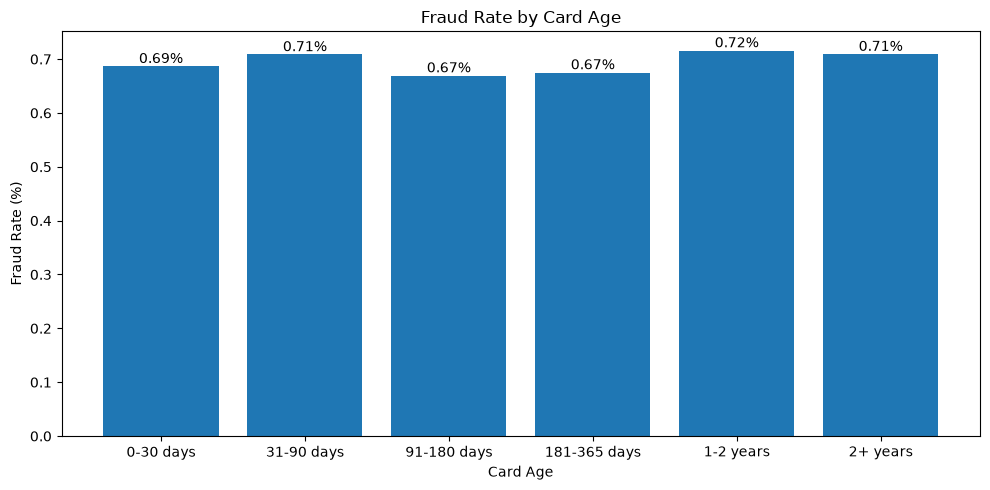

In [41]:
# Visualization 6: Fraud rate by card age

plt.figure(figsize=(10, 5))

plt.bar(
    card_age_analysis["card_age_band"].astype(str),
    card_age_analysis["fraud_rate_pct"]
)

plt.title("Fraud Rate by Card Age")
plt.xlabel("Card Age")
plt.ylabel("Fraud Rate (%)")

for i, value in enumerate(card_age_analysis["fraud_rate_pct"]):
    plt.text(
        i,
        value,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [24]:
# Cell 19: Inspect transaction location fields

print(transactions.columns.tolist())

display(
    transactions[
        [
            "txn_id",
            "customer_id",
            "card_id",
            "merchant_id",
            "merchant_city",
            "merchant_country",
            "ip_country",
            "customer_home_city",
            "channel",
            "category",
            "amount"
        ]
    ].head()
)

['txn_id', 'card_id', 'customer_id', 'merchant_id', 'device_id', 'txn_ts', 'amount', 'channel', 'category', 'merchant_city', 'merchant_country', 'ip_country', 'auth_result', 'customer_home_city', 'is_fraud', 'txn_hour', 'card_type', 'issue_date', 'credit_limit', 'card_age_days', 'card_age_months', 'card_age_band']


,txn_id,customer_id,card_id,merchant_id,merchant_city,merchant_country,ip_country,customer_home_city,channel,category,amount
0,1,6694,10359,554,Chandigarh,India,India,Ahmedabad,E_COMMERCE,Fuel,"2,253.14"
1,2,9196,20959,1643,Kolkata,India,India,Chandigarh,POS,Clothing,"6,113.61"
2,3,12095,3769,500,Mumbai,India,USA,Delhi,E_COMMERCE,Online Services,"1,019.19"
3,4,12480,3632,724,Chandigarh,India,India,Chennai,E_COMMERCE,Entertainment,"1,447.45"
4,5,2880,11165,26,Ahmedabad,India,India,Jaipur,E_COMMERCE,Entertainment,"1,534.02"


In [25]:
# Cell 20: Inspect country fields

print("Merchant countries:")
display(
    transactions["merchant_country"]
    .value_counts(dropna=False)
)

print("\nIP countries:")
display(
    transactions["ip_country"]
    .value_counts(dropna=False)
)

Merchant countries:


merchant_country
India        1327409
USA            57856
UK             43116
Singapore      36582
UAE            33390
Name: count, dtype: int64


IP countries:


ip_country
India        1417526
USA            23155
UAE            18836
UK             18488
Singapore      17353
UNKNOWN         2995
Name: count, dtype: int64

In [26]:
# Cell 21: Country mismatch analysis

# UNKNOWN IP country is not treated as a mismatch
transactions["country_mismatch"] = (
    (transactions["ip_country"] != transactions["merchant_country"]) &
    (transactions["ip_country"] != "UNKNOWN")
)

print(
    transactions["country_mismatch"]
    .value_counts()
)

print("\nMismatch percentage:")
print(
    transactions["country_mismatch"].mean() * 100
)

country_mismatch
False    1263686
True      234667
Name: count, dtype: int64

Mismatch percentage:
15.661663172830433


In [27]:
# Cell 22: Fraud performance of country mismatch

country_mismatch_analysis = (
    transactions
    .groupby("country_mismatch")
    .agg(
        transactions=("txn_id", "count"),
        transaction_value=("amount", "sum"),
        fraud_transactions=("is_fraud", "sum"),
        fraud_value=("amount", lambda x: x[transactions.loc[x.index, "is_fraud"] == 1].sum())
    )
    .reset_index()
)

country_mismatch_analysis["fraud_rate_pct"] = (
    country_mismatch_analysis["fraud_transactions"]
    / country_mismatch_analysis["transactions"]
    * 100
)

country_mismatch_analysis["fraud_value_pct"] = (
    country_mismatch_analysis["fraud_value"]
    / country_mismatch_analysis["transaction_value"]
    * 100
)

display(country_mismatch_analysis)

,country_mismatch,transactions,transaction_value,fraud_transactions,fraud_value,fraud_rate_pct,fraud_value_pct
0,False,1263686,"3,173,462,068.11",7628,"77,135,326.78",0.60,2.43
1,True,234667,"589,348,555.88",2860,"18,062,533.56",1.22,3.06


In [28]:
# Cell 23: Country mismatch combinations

mismatch_pairs = (
    transactions[
        transactions["country_mismatch"]
    ]
    .groupby(
        ["ip_country", "merchant_country"]
    )
    .agg(
        transactions=("txn_id", "count"),
        transaction_value=("amount", "sum"),
        fraud_transactions=("is_fraud", "sum"),
        fraud_value=("amount", lambda x: x[transactions.loc[x.index, "is_fraud"] == 1].sum())
    )
    .reset_index()
)

mismatch_pairs["fraud_rate_pct"] = (
    mismatch_pairs["fraud_transactions"]
    / mismatch_pairs["transactions"]
    * 100
)

mismatch_pairs = mismatch_pairs.sort_values(
    "fraud_rate_pct",
    ascending=False
)

display(mismatch_pairs)

,ip_country,merchant_country,transactions,transaction_value,fraud_transactions,fraud_value,fraud_rate_pct
15,UK,USA,680,"1,636,706.12",34,"112,966.91",5.00
5,Singapore,UAE,393,"1,180,218.26",17,"314,331.19",4.33
6,Singapore,UK,486,"1,221,673.79",21,"82,670.08",4.32
19,USA,UK,668,"1,833,317.85",23,"179,200.29",3.44
4,Singapore,India,15039,"37,384,133.55",497,"1,964,968.80",3.30
7,Singapore,USA,646,"1,795,943.68",21,"148,122.49",3.25
12,UK,India,16103,"40,935,145.39",484,"2,072,313.07",3.01
8,UAE,India,16342,"40,727,242.91",484,"1,912,050.55",2.96
18,USA,UAE,488,"1,404,201.76",13,"55,811.12",2.66
14,UK,UAE,379,"900,547.12",10,"41,220.34",2.64


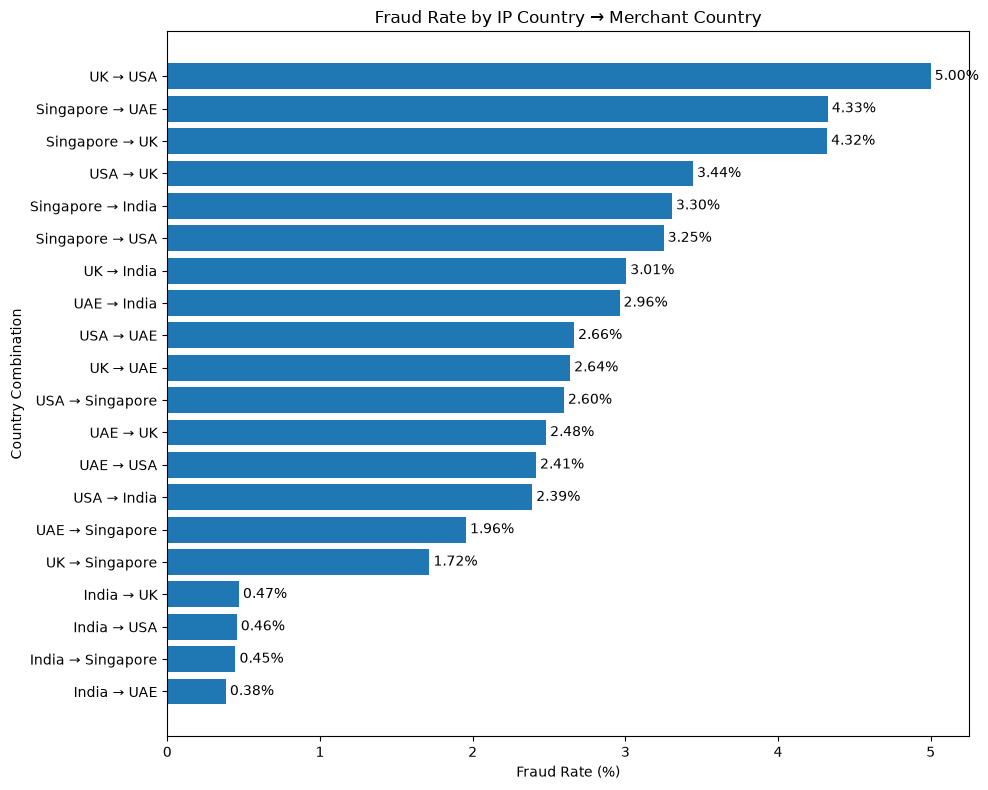

In [43]:
# Visualization 8: Fraud rate by IP → merchant country combination

plot_data = mismatch_pairs.sort_values(
    "fraud_rate_pct",
    ascending=True
)

plot_data["country_pair"] = (
    plot_data["ip_country"]
    + " → "
    + plot_data["merchant_country"]
)

plt.figure(figsize=(10, 8))

plt.barh(
    plot_data["country_pair"],
    plot_data["fraud_rate_pct"]
)

plt.title("Fraud Rate by IP Country → Merchant Country")
plt.xlabel("Fraud Rate (%)")
plt.ylabel("Country Combination")

for i, value in enumerate(plot_data["fraud_rate_pct"]):
    plt.text(
        value,
        i,
        f" {value:.2f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

In [29]:
# Cell 24: Customer home city vs merchant city mismatch

transactions["city_mismatch"] = (
    transactions["customer_home_city"] != transactions["merchant_city"]
)

city_mismatch_analysis = (
    transactions
    .groupby("city_mismatch")
    .agg(
        transactions=("txn_id", "count"),
        transaction_value=("amount", "sum"),
        fraud_transactions=("is_fraud", "sum"),
        fraud_value=("amount", lambda x: x[
            transactions.loc[x.index, "is_fraud"] == 1
        ].sum())
    )
    .reset_index()
)

city_mismatch_analysis["fraud_rate_pct"] = (
    city_mismatch_analysis["fraud_transactions"]
    / city_mismatch_analysis["transactions"]
    * 100
)

city_mismatch_analysis["fraud_value_pct"] = (
    city_mismatch_analysis["fraud_value"]
    / city_mismatch_analysis["transaction_value"]
    * 100
)

display(city_mismatch_analysis)

,city_mismatch,transactions,transaction_value,fraud_transactions,fraud_value,fraud_rate_pct,fraud_value_pct
0,False,100965,"254,690,195.58",702,"7,139,545.36",0.70,2.80
1,True,1397388,"3,508,120,428.41",9786,"88,058,314.98",0.70,2.51


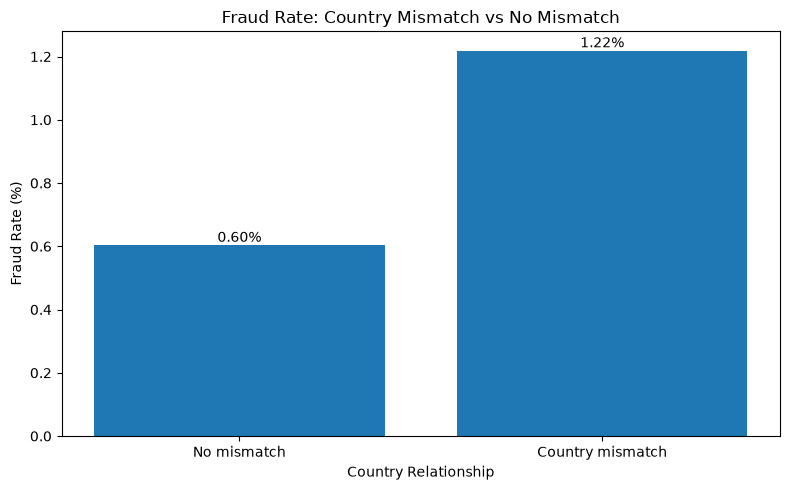

In [42]:
# Visualization 7: Fraud rate by country mismatch

plot_data = country_mismatch_analysis.copy()

plot_data["label"] = plot_data["country_mismatch"].map({
    False: "No mismatch",
    True: "Country mismatch"
})

plt.figure(figsize=(8, 5))

plt.bar(
    plot_data["label"],
    plot_data["fraud_rate_pct"]
)

plt.title("Fraud Rate: Country Mismatch vs No Mismatch")
plt.xlabel("Country Relationship")
plt.ylabel("Fraud Rate (%)")

for i, value in enumerate(plot_data["fraud_rate_pct"]):
    plt.text(
        i,
        value,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [30]:
# Cell 25: City mismatch volume

print("City mismatch transactions:")
print(
    transactions["city_mismatch"].value_counts()
)

print("\nCity mismatch percentage:")
print(
    transactions["city_mismatch"].mean() * 100
)

City mismatch transactions:
city_mismatch
True     1397388
False     100965
Name: count, dtype: int64

City mismatch percentage:
93.2616012381595


In [31]:
# Cell 26: Create transaction amount bands

transactions["amount_band"] = pd.cut(
    transactions["amount"],
    bins=[0, 500, 1000, 5000, 10000, 25000, 50000, 100000, float("inf")],
    labels=[
        "₹0-500",
        "₹501-1K",
        "₹1K-5K",
        "₹5K-10K",
        "₹10K-25K",
        "₹25K-50K",
        "₹50K-100K",
        "₹100K+"
    ]
)

display(
    transactions["amount_band"]
    .value_counts()
    .sort_index()
)

amount_band
₹0-500       207982
₹501-1K      308868
₹1K-5K       808197
₹5K-10K      127616
₹10K-25K      40897
₹25K-50K       4146
₹50K-100K       584
₹100K+           63
Name: count, dtype: int64

In [32]:
# Cell 27: Fraud analysis by transaction value

amount_analysis = (
    transactions
    .groupby("amount_band", observed=True)
    .agg(
        transactions=("txn_id", "count"),
        transaction_value=("amount", "sum"),
        fraud_transactions=("is_fraud", "sum"),
        fraud_value=("amount", lambda x: x[
            transactions.loc[x.index, "is_fraud"] == 1
        ].sum())
    )
    .reset_index()
)

amount_analysis["fraud_rate_pct"] = (
    amount_analysis["fraud_transactions"]
    / amount_analysis["transactions"]
    * 100
)

amount_analysis["fraud_value_pct"] = (
    amount_analysis["fraud_value"]
    / amount_analysis["transaction_value"]
    * 100
)

display(amount_analysis)

,amount_band,transactions,transaction_value,fraud_transactions,fraud_value,fraud_rate_pct,fraud_value_pct
0,₹0-500,207982,"67,048,716.94",2484,"203,643.61",1.19,0.30
1,₹501-1K,308868,"229,233,425.98",809,"608,256.95",0.26,0.27
2,₹1K-5K,808197,"1,843,294,813.54",3263,"8,308,330.89",0.40,0.45
3,₹5K-10K,127616,"866,638,851.57",1304,"9,185,564.52",1.02,1.06
4,₹10K-25K,40897,"576,040,215.59",1483,"23,708,286.11",3.63,4.12
5,₹25K-50K,4146,"134,957,754.44",813,"28,357,680.13",19.61,21.01
6,₹50K-100K,584,"37,403,544.10",284,"18,431,871.52",48.63,49.28
7,₹100K+,63,"8,193,301.83",48,"6,394,226.61",76.19,78.04


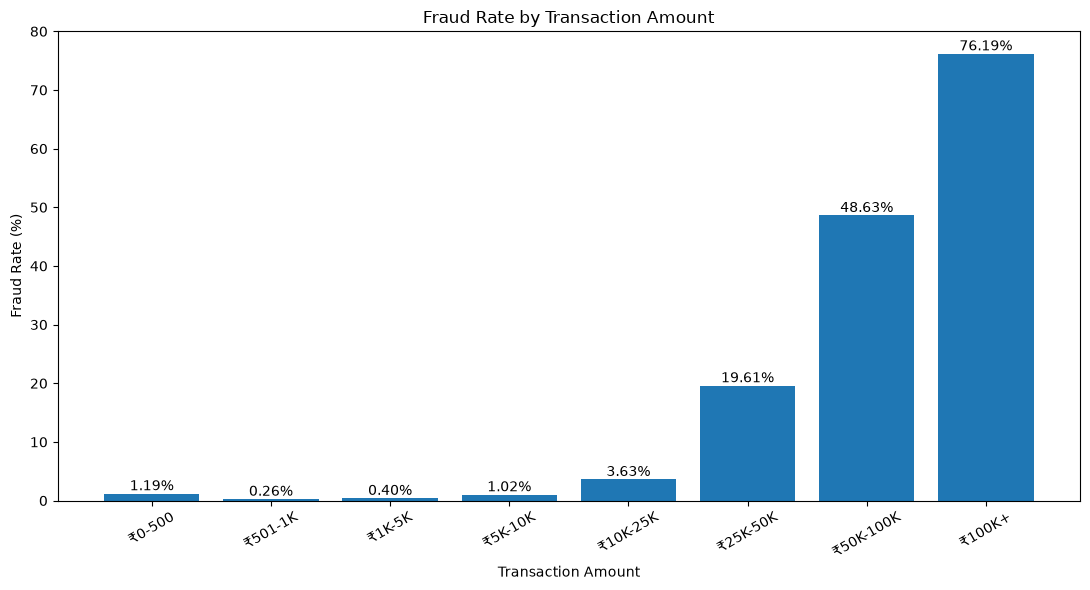

In [44]:
# Visualization 9: Fraud rate by transaction amount

plt.figure(figsize=(11, 6))

plt.bar(
    amount_analysis["amount_band"].astype(str),
    amount_analysis["fraud_rate_pct"]
)

plt.title("Fraud Rate by Transaction Amount")
plt.xlabel("Transaction Amount")
plt.ylabel("Fraud Rate (%)")

for i, value in enumerate(amount_analysis["fraud_rate_pct"]):
    plt.text(
        i,
        value,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [33]:
# Cell 28: Fraud value concentration

total_fraud_value = transactions.loc[
    transactions["is_fraud"] == 1,
    "amount"
].sum()

amount_analysis["share_of_total_fraud_value_pct"] = (
    amount_analysis["fraud_value"]
    / total_fraud_value
    * 100
)

display(
    amount_analysis[
        [
            "amount_band",
            "transactions",
            "fraud_transactions",
            "fraud_rate_pct",
            "fraud_value",
            "share_of_total_fraud_value_pct"
        ]
    ]
)

,amount_band,transactions,fraud_transactions,fraud_rate_pct,fraud_value,share_of_total_fraud_value_pct
0,₹0-500,207982,2484,1.19,"203,643.61",0.21
1,₹501-1K,308868,809,0.26,"608,256.95",0.64
2,₹1K-5K,808197,3263,0.40,"8,308,330.89",8.73
3,₹5K-10K,127616,1304,1.02,"9,185,564.52",9.65
4,₹10K-25K,40897,1483,3.63,"23,708,286.11",24.90
5,₹25K-50K,4146,813,19.61,"28,357,680.13",29.79
6,₹50K-100K,584,284,48.63,"18,431,871.52",19.36
7,₹100K+,63,48,76.19,"6,394,226.61",6.72


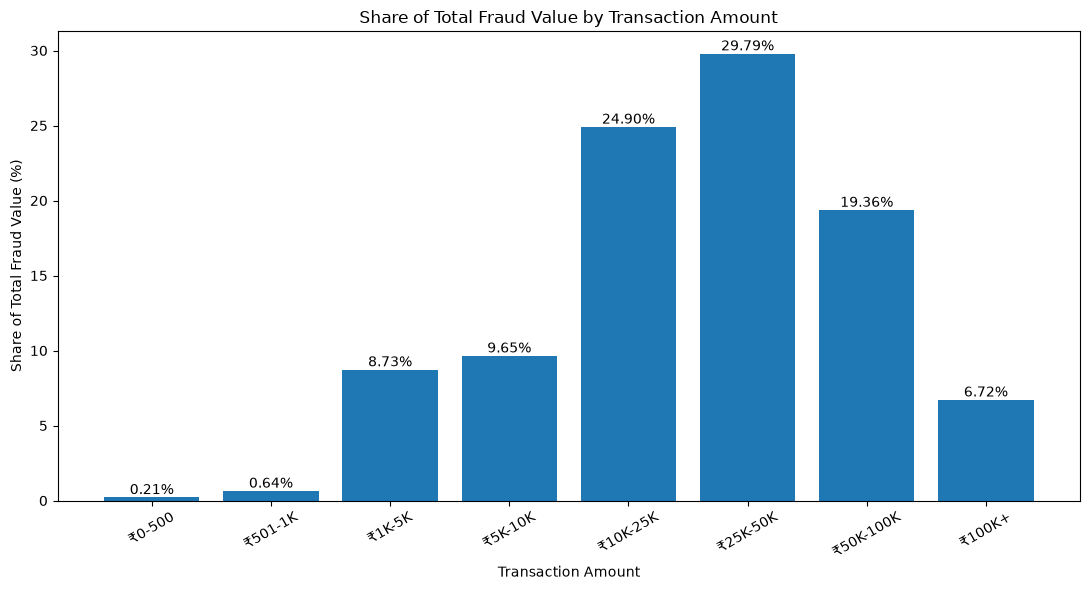

In [45]:
# Visualization 10: Share of total fraud value by amount band

plt.figure(figsize=(11, 6))

plt.bar(
    amount_analysis["amount_band"].astype(str),
    amount_analysis["share_of_total_fraud_value_pct"]
)

plt.title("Share of Total Fraud Value by Transaction Amount")
plt.xlabel("Transaction Amount")
plt.ylabel("Share of Total Fraud Value (%)")

for i, value in enumerate(
    amount_analysis["share_of_total_fraud_value_pct"]
):
    plt.text(
        i,
        value,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [46]:
# Cell 29: Prepare transaction velocity analysis

transactions = transactions.sort_values(
    ["card_id", "txn_ts"]
).reset_index(drop=True)

print("Transactions:", len(transactions))
print("Unique cards:", transactions["card_id"].nunique())

Transactions: 1498353
Unique cards: 30000


In [47]:
# Cell 30: Calculate 10-minute transaction velocity per card

transactions["velocity_10m"] = (
    transactions
    .groupby("card_id", group_keys=False)
    .apply(
        lambda group: (
            group.set_index("txn_ts")["txn_id"]
            .rolling("10min")
            .count()
            .values
        ),
        include_groups=False
    )
    .explode()
    .astype(float)
    .values
)

print("10-minute velocity calculated.")
print(
    transactions["velocity_10m"].describe()
)

10-minute velocity calculated.
count   1,498,353.00
mean            1.00
std             0.03
min             1.00
25%             1.00
50%             1.00
75%             1.00
max             3.00
Name: velocity_10m, dtype: float64


In [48]:
# Cell 31: Calculate 1-hour transaction velocity per card

transactions["velocity_1h"] = (
    transactions
    .groupby("card_id", group_keys=False)
    .apply(
        lambda group: (
            group.set_index("txn_ts")["txn_id"]
            .rolling("1h")
            .count()
            .values
        ),
        include_groups=False
    )
    .explode()
    .astype(float)
    .values
)

print("1-hour velocity calculated.")
print(
    transactions["velocity_1h"].describe()
)

1-hour velocity calculated.
count   1,498,353.00
mean            1.01
std             0.08
min             1.00
25%             1.00
50%             1.00
75%             1.00
max             3.00
Name: velocity_1h, dtype: float64


In [49]:
# Cell 32: Calculate 24-hour transaction velocity per card

transactions["velocity_24h"] = (
    transactions
    .groupby("card_id", group_keys=False)
    .apply(
        lambda group: (
            group.set_index("txn_ts")["txn_id"]
            .rolling("24h")
            .count()
            .values
        ),
        include_groups=False
    )
    .explode()
    .astype(float)
    .values
)

print("24-hour velocity calculated.")
print(
    transactions["velocity_24h"].describe()
)

24-hour velocity calculated.
count   1,498,353.00
mean            1.14
std             0.37
min             1.00
25%             1.00
50%             1.00
75%             1.00
max             6.00
Name: velocity_24h, dtype: float64


In [50]:
# Cell 33: Create velocity bands

transactions["velocity_10m_band"] = pd.cut(
    transactions["velocity_10m"],
    bins=[0, 1, 2, float("inf")],
    labels=[
        "1 transaction",
        "2 transactions",
        "3+ transactions"
    ]
)

transactions["velocity_1h_band"] = pd.cut(
    transactions["velocity_1h"],
    bins=[0, 1, 2, float("inf")],
    labels=[
        "1 transaction",
        "2 transactions",
        "3+ transactions"
    ]
)

transactions["velocity_24h_band"] = pd.cut(
    transactions["velocity_24h"],
    bins=[0, 1, 2, 3, 5, float("inf")],
    labels=[
        "1 transaction",
        "2 transactions",
        "3 transactions",
        "4-5 transactions",
        "6+ transactions"
    ]
)

print("Velocity bands created.")

Velocity bands created.


In [51]:
# Cell 34: Fraud analysis by 10-minute velocity

velocity_10m_analysis = (
    transactions
    .groupby("velocity_10m_band", observed=True)
    .agg(
        transactions=("txn_id", "count"),
        transaction_value=("amount", "sum"),
        fraud_transactions=("is_fraud", "sum"),
        fraud_value=("amount", lambda x: x[
            transactions.loc[x.index, "is_fraud"] == 1
        ].sum())
    )
    .reset_index()
)

velocity_10m_analysis["fraud_rate_pct"] = (
    velocity_10m_analysis["fraud_transactions"]
    / velocity_10m_analysis["transactions"]
    * 100
)

velocity_10m_analysis["fraud_value_pct"] = (
    velocity_10m_analysis["fraud_value"]
    / velocity_10m_analysis["transaction_value"]
    * 100
)

display(velocity_10m_analysis)

,velocity_10m_band,transactions,transaction_value,fraud_transactions,fraud_value,fraud_rate_pct,fraud_value_pct
0,1 transaction,1496866,"3,759,060,409.39",10482,"95,101,485.26",0.70,2.53
1,2 transactions,1486,"3,747,604.98",6,"96,375.08",0.40,2.57
2,3+ transactions,1,"2,609.62",0,0.00,0.00,0.00


In [52]:
# Cell 35: Fraud analysis by 1-hour velocity

velocity_1h_analysis = (
    transactions
    .groupby("velocity_1h_band", observed=True)
    .agg(
        transactions=("txn_id", "count"),
        transaction_value=("amount", "sum"),
        fraud_transactions=("is_fraud", "sum"),
        fraud_value=("amount", lambda x: x[
            transactions.loc[x.index, "is_fraud"] == 1
        ].sum())
    )
    .reset_index()
)

velocity_1h_analysis["fraud_rate_pct"] = (
    velocity_1h_analysis["fraud_transactions"]
    / velocity_1h_analysis["transactions"]
    * 100
)

velocity_1h_analysis["fraud_value_pct"] = (
    velocity_1h_analysis["fraud_value"]
    / velocity_1h_analysis["transaction_value"]
    * 100
)

display(velocity_1h_analysis)

,velocity_1h_band,transactions,transaction_value,fraud_transactions,fraud_value,fraud_rate_pct,fraud_value_pct
0,1 transaction,1489825,"3,741,630,121.33",10429,"94,821,109.19",0.70,2.53
1,2 transactions,8503,"21,119,175.16",59,"376,751.15",0.69,1.78
2,3+ transactions,25,"61,327.50",0,0.00,0.00,0.00


In [53]:
# Cell 36: Fraud analysis by 24-hour velocity

velocity_24h_analysis = (
    transactions
    .groupby("velocity_24h_band", observed=True)
    .agg(
        transactions=("txn_id", "count"),
        transaction_value=("amount", "sum"),
        fraud_transactions=("is_fraud", "sum"),
        fraud_value=("amount", lambda x: x[
            transactions.loc[x.index, "is_fraud"] == 1
        ].sum())
    )
    .reset_index()
)

velocity_24h_analysis["fraud_rate_pct"] = (
    velocity_24h_analysis["fraud_transactions"]
    / velocity_24h_analysis["transactions"]
    * 100
)

velocity_24h_analysis["fraud_value_pct"] = (
    velocity_24h_analysis["fraud_value"]
    / velocity_24h_analysis["transaction_value"]
    * 100
)

display(velocity_24h_analysis)

,velocity_24h_band,transactions,transaction_value,fraud_transactions,fraud_value,fraud_rate_pct,fraud_value_pct
0,1 transaction,1307312,"3,283,668,484.19",9262,"83,713,829.24",0.71,2.55
1,2 transactions,178444,"447,878,462.53",1131,"10,713,457.53",0.63,2.39
2,3 transactions,12036,"29,900,995.35",91,"762,550.22",0.76,2.55
3,4-5 transactions,560,"1,361,881.11",4,"8,023.35",0.71,0.59
4,6+ transactions,1,800.81,0,0.00,0.00,0.00


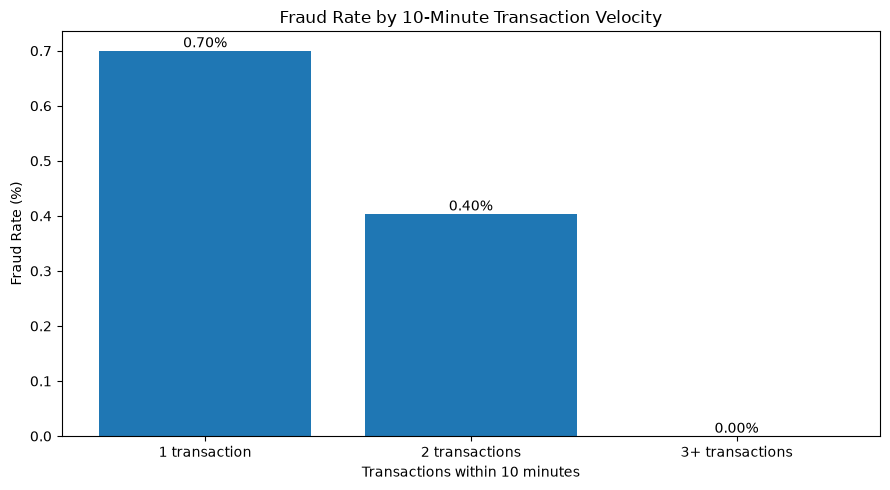

In [54]:
# Cell 37: Visualization - 10-minute velocity fraud rate

plt.figure(figsize=(9, 5))

plt.bar(
    velocity_10m_analysis["velocity_10m_band"].astype(str),
    velocity_10m_analysis["fraud_rate_pct"]
)

plt.title("Fraud Rate by 10-Minute Transaction Velocity")
plt.xlabel("Transactions within 10 minutes")
plt.ylabel("Fraud Rate (%)")

for i, value in enumerate(velocity_10m_analysis["fraud_rate_pct"]):
    plt.text(
        i,
        value,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

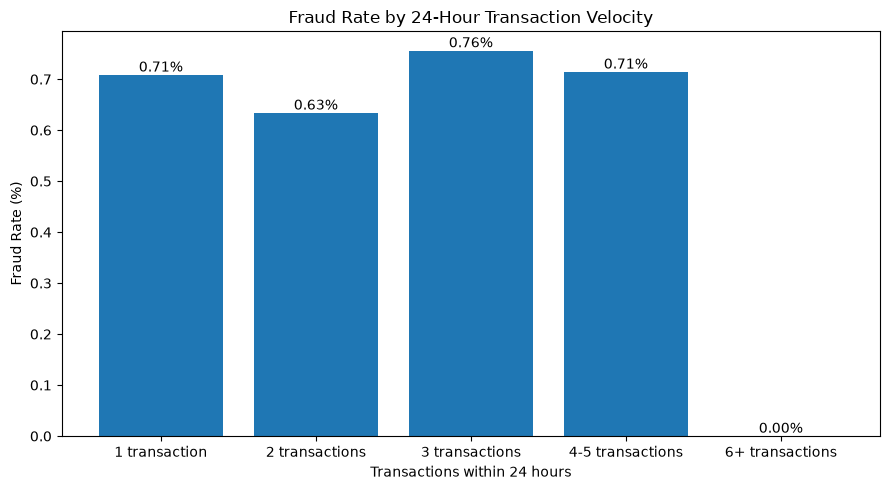

In [55]:
# Cell 38: Visualization - 24-hour velocity fraud rate

plt.figure(figsize=(9, 5))

plt.bar(
    velocity_24h_analysis["velocity_24h_band"].astype(str),
    velocity_24h_analysis["fraud_rate_pct"]
)

plt.title("Fraud Rate by 24-Hour Transaction Velocity")
plt.xlabel("Transactions within 24 hours")
plt.ylabel("Fraud Rate (%)")

for i, value in enumerate(velocity_24h_analysis["fraud_rate_pct"]):
    plt.text(
        i,
        value,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

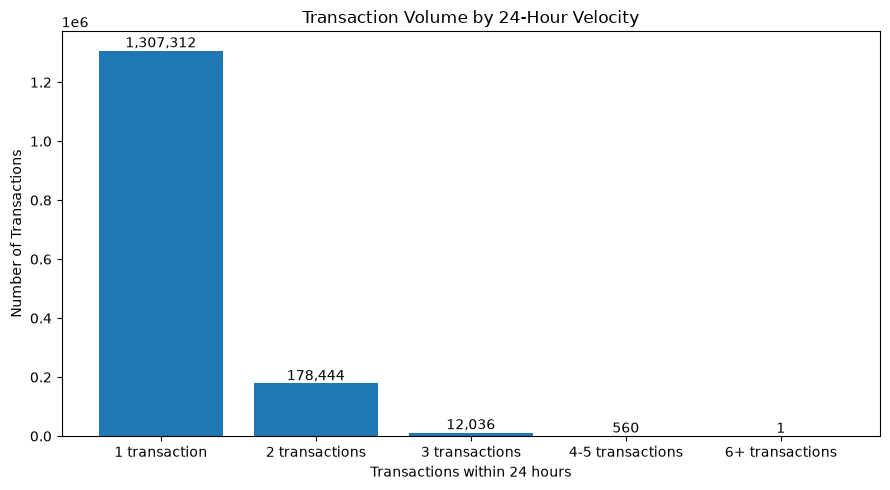

In [56]:
# Cell 39: Transaction volume by 24-hour velocity

plt.figure(figsize=(9, 5))

plt.bar(
    velocity_24h_analysis["velocity_24h_band"].astype(str),
    velocity_24h_analysis["transactions"]
)

plt.title("Transaction Volume by 24-Hour Velocity")
plt.xlabel("Transactions within 24 hours")
plt.ylabel("Number of Transactions")

for i, value in enumerate(velocity_24h_analysis["transactions"]):
    plt.text(
        i,
        value,
        f"{value:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [57]:
# Cell 40: Create transaction month

transactions["txn_month"] = transactions["txn_ts"].dt.to_period("M")

print(
    "Months in dataset:",
    transactions["txn_month"].nunique()
)

print(
    transactions["txn_month"].min(),
    "to",
    transactions["txn_month"].max()
)

Months in dataset: 12
2025-01 to 2025-12


In [58]:
# Cell 41: Monthly fraud and transaction analysis

monthly_analysis = (
    transactions
    .groupby("txn_month")
    .agg(
        transactions=("txn_id", "count"),
        transaction_value=("amount", "sum"),
        fraud_transactions=("is_fraud", "sum"),
        fraud_value=("amount", lambda x: x[
            transactions.loc[x.index, "is_fraud"] == 1
        ].sum())
    )
    .reset_index()
)

monthly_analysis["fraud_rate_pct"] = (
    monthly_analysis["fraud_transactions"]
    / monthly_analysis["transactions"]
    * 100
)

monthly_analysis["fraud_value_pct"] = (
    monthly_analysis["fraud_value"]
    / monthly_analysis["transaction_value"]
    * 100
)

display(monthly_analysis)

,txn_month,transactions,transaction_value,fraud_transactions,fraud_value,fraud_rate_pct,fraud_value_pct
0,2025-01,127340,"308,037,939.01",926,"7,783,767.62",0.73,2.53
1,2025-02,115381,"279,584,475.73",773,"6,313,373.34",0.67,2.26
2,2025-03,127437,"312,746,771.89",906,"7,868,828.94",0.71,2.52
3,2025-04,123235,"298,254,222.75",850,"7,582,866.01",0.69,2.54
4,2025-05,127197,"309,750,274.28",897,"7,935,379.90",0.71,2.56
5,2025-06,123669,"302,386,128.32",884,"8,747,508.26",0.71,2.89
6,2025-07,127143,"310,412,612.74",873,"9,106,609.84",0.69,2.93
7,2025-08,126537,"308,020,593.05",855,"8,070,341.27",0.68,2.62
8,2025-09,122745,"297,553,413.26",859,"7,781,842.53",0.70,2.62
9,2025-10,127325,"367,561,486.71",897,"7,614,749.13",0.70,2.07


In [59]:
# Cell 42: Monthly chargeback loss

chargebacks["reported_date"] = pd.to_datetime(
    chargebacks["reported_date"],
    errors="coerce"
)

chargebacks["chargeback_month"] = (
    chargebacks["reported_date"].dt.to_period("M")
)

monthly_chargeback = (
    chargebacks
    .groupby("chargeback_month")
    .agg(
        chargeback_records=("txn_id", "count"),
        gross_loss=("loss_amount", "sum"),
        recovered_amount=("recovered_amount", "sum")
    )
    .reset_index()
)

monthly_chargeback["net_loss"] = (
    monthly_chargeback["gross_loss"]
    - monthly_chargeback["recovered_amount"]
)

display(monthly_chargeback)

,chargeback_month,chargeback_records,gross_loss,recovered_amount,net_loss
0,2025-01,228,"1,891,945.54","559,407.96","1,332,537.58"
1,2025-02,745,"6,239,485.21","1,746,314.96","4,493,170.25"
2,2025-03,869,"7,466,480.00","1,941,287.68","5,525,192.32"
3,2025-04,913,"7,669,730.85","2,125,079.26","5,544,651.59"
4,2025-05,856,"7,990,556.44","2,072,076.57","5,918,479.87"
5,2025-06,853,"7,637,632.76","2,178,797.67","5,458,835.09"
6,2025-07,943,"9,416,188.15","2,658,382.48","6,757,805.67"
7,2025-08,838,"8,650,146.83","2,497,538.61","6,152,608.22"
8,2025-09,863,"7,082,862.93","1,970,291.14","5,112,571.79"
9,2025-10,910,"9,001,888.33","2,506,708.08","6,495,180.25"


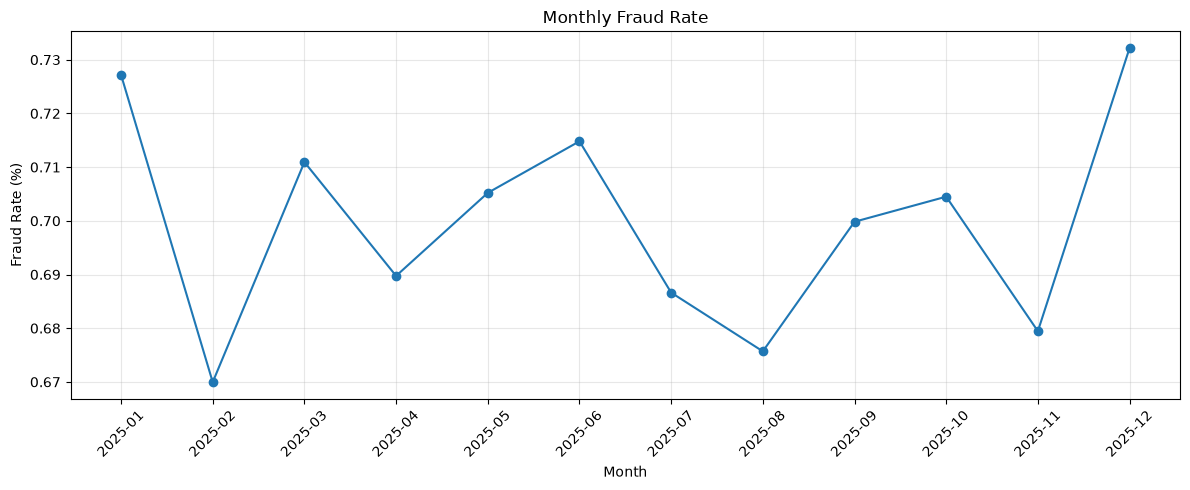

In [60]:
# Cell 43: Visualization - monthly fraud rate

plot_data = monthly_analysis.copy()

plot_data["month"] = (
    plot_data["txn_month"]
    .astype(str)
)

plt.figure(figsize=(12, 5))

plt.plot(
    plot_data["month"],
    plot_data["fraud_rate_pct"],
    marker="o"
)

plt.title("Monthly Fraud Rate")
plt.xlabel("Month")
plt.ylabel("Fraud Rate (%)")

plt.xticks(rotation=45)

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

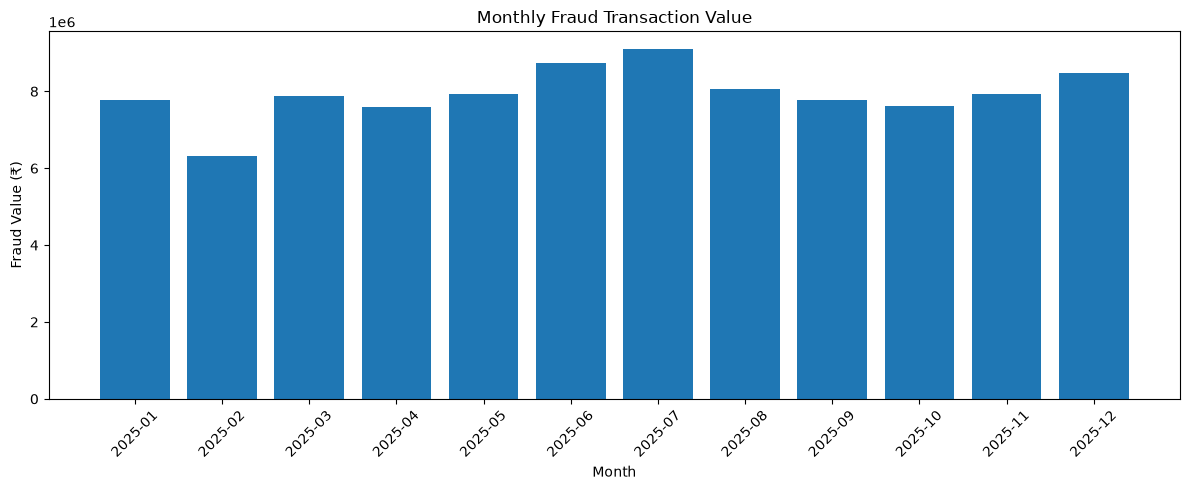

In [61]:
# Cell 44: Visualization - monthly fraud value

plt.figure(figsize=(12, 5))

plt.bar(
    plot_data["month"],
    plot_data["fraud_value"]
)

plt.title("Monthly Fraud Transaction Value")
plt.xlabel("Month")
plt.ylabel("Fraud Value (₹)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

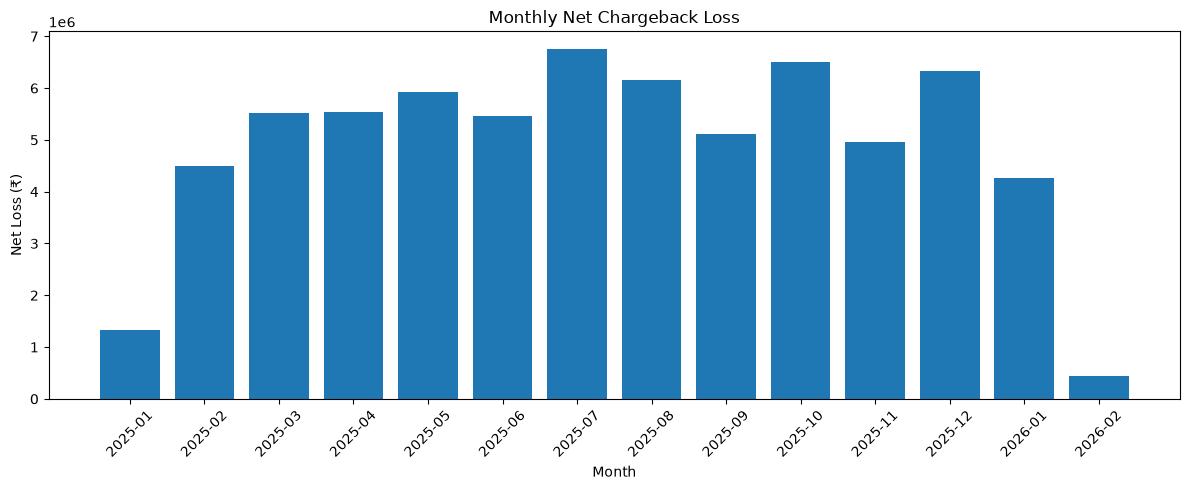

In [62]:
# Cell 45: Visualization - monthly net chargeback loss

plot_loss = monthly_chargeback.copy()

plot_loss["month"] = (
    plot_loss["chargeback_month"]
    .astype(str)
)

plt.figure(figsize=(12, 5))

plt.bar(
    plot_loss["month"],
    plot_loss["net_loss"]
)

plt.title("Monthly Net Chargeback Loss")
plt.xlabel("Month")
plt.ylabel("Net Loss (₹)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [63]:
chargebacks["reported_date"]

0       2025-08-12 23:59:18
1       2025-03-09 21:22:58
2       2025-07-26 14:14:10
3       2025-04-15 06:02:41
4       2025-07-20 19:51:58
                ...        
10495   2025-12-23 23:50:06
10496   2026-01-10 05:03:08
10497   2025-08-19 19:42:40
10498   2025-06-19 20:48:55
10499   2025-09-24 09:00:12
Name: reported_date, Length: 10500, dtype: datetime64[us]

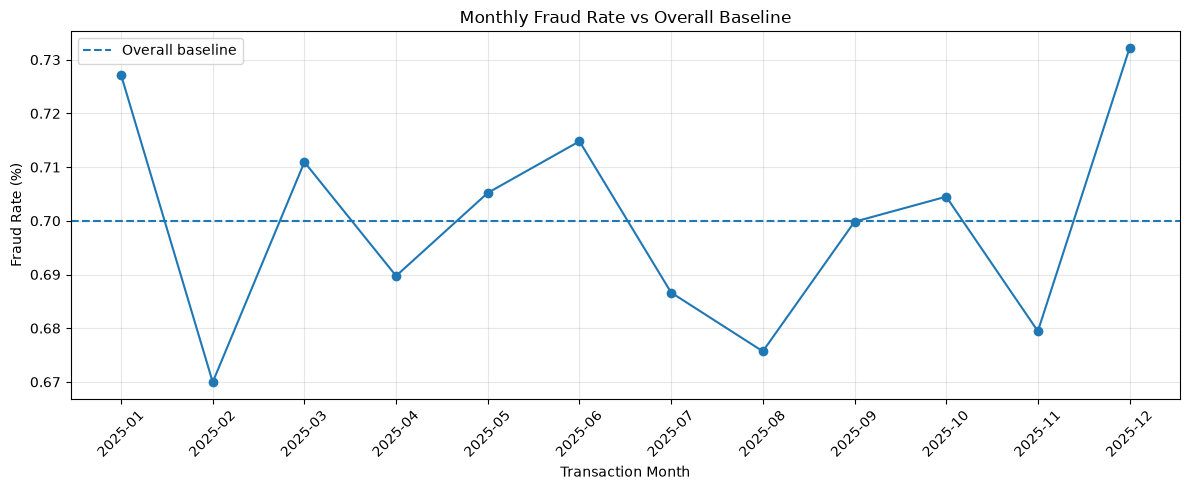

In [64]:
# Cell 46: Monthly fraud rate visualization

plot_data = monthly_analysis.copy()

plot_data["month"] = plot_data["txn_month"].astype(str)

plt.figure(figsize=(12, 5))

plt.plot(
    plot_data["month"],
    plot_data["fraud_rate_pct"],
    marker="o"
)

plt.axhline(
    y=transactions["is_fraud"].mean() * 100,
    linestyle="--",
    label="Overall baseline"
)

plt.title("Monthly Fraud Rate vs Overall Baseline")
plt.xlabel("Transaction Month")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [66]:
# Cell 48: Create candidate risk indicators

transactions["is_high_value_10k"] = (
    transactions["amount"] >= 10000
)

transactions["is_high_value_25k"] = (
    transactions["amount"] >= 25000
)

transactions["is_high_value_50k"] = (
    transactions["amount"] >= 50000
)

transactions["is_ecommerce"] = (
    transactions["channel"] == "E_COMMERCE"
)

transactions["is_high_risk_category"] = (
    transactions["category"].isin(
        ["Electronics", "Gift Cards"]
    )
)

transactions["is_country_mismatch"] = (
    transactions["country_mismatch"]
)

print("Candidate indicators created.")

Candidate indicators created.


In [67]:
# Cell 49: Candidate pattern analysis

patterns = {
    "E-commerce": transactions["is_ecommerce"],

    "High value >= ₹10K": transactions["is_high_value_10k"],

    "High value >= ₹25K": transactions["is_high_value_25k"],

    "Country mismatch": transactions["is_country_mismatch"],

    "High-risk category": transactions["is_high_risk_category"],

    "E-commerce + high-risk category":
        transactions["is_ecommerce"] &
        transactions["is_high_risk_category"],

    "Country mismatch + high value >= ₹10K":
        transactions["is_country_mismatch"] &
        transactions["is_high_value_10k"],

    "E-commerce + high value >= ₹10K":
        transactions["is_ecommerce"] &
        transactions["is_high_value_10k"],

    "E-commerce + high-risk category + high value >= ₹10K":
        transactions["is_ecommerce"] &
        transactions["is_high_risk_category"] &
        transactions["is_high_value_10k"]
}

pattern_results = []

for pattern_name, mask in patterns.items():

    pattern_transactions = transactions.loc[mask]

    txn_count = len(pattern_transactions)

    txn_value = pattern_transactions["amount"].sum()

    fraud_count = pattern_transactions["is_fraud"].sum()

    fraud_value = pattern_transactions.loc[
        pattern_transactions["is_fraud"] == 1,
        "amount"
    ].sum()

    fraud_rate = (
        fraud_count / txn_count * 100
        if txn_count > 0 else 0
    )

    fraud_value_share = (
        fraud_value / txn_value * 100
        if txn_value > 0 else 0
    )

    pattern_results.append({
        "pattern": pattern_name,
        "transactions": txn_count,
        "transaction_value": txn_value,
        "fraud_transactions": fraud_count,
        "fraud_value": fraud_value,
        "fraud_rate_pct": fraud_rate,
        "fraud_value_pct": fraud_value_share
    })

pattern_analysis = pd.DataFrame(pattern_results)

display(
    pattern_analysis.sort_values(
        "fraud_rate_pct",
        ascending=False
    )
)

,pattern,transactions,transaction_value,fraud_transactions,fraud_value,fraud_rate_pct,fraud_value_pct
8,E-commerce + high-risk category + high value >...,4938,"112,321,243.11",1987,"65,862,706.81",40.24,58.64
2,High value >= ₹25K,4794,"180,579,600.37",1145,"53,183,778.26",23.88,29.45
7,E-commerce + high value >= ₹10K,18629,"329,499,981.15",2224,"69,776,150.03",11.94,21.18
6,Country mismatch + high value >= ₹10K,7146,"118,502,499.68",437,"12,559,054.23",6.12,10.60
1,High value >= ₹10K,45690,"756,594,815.96",2628,"76,892,064.37",5.75,10.16
5,E-commerce + high-risk category,101916,"313,834,285.59",3206,"69,136,297.64",3.15,22.03
4,High-risk category,262601,"712,690,552.48",3683,"71,914,952.60",1.40,10.09
0,E-commerce,572928,"1,475,482,560.90",7705,"79,988,283.24",1.34,5.42
3,Country mismatch,234667,"589,348,555.88",2860,"18,062,533.56",1.22,3.06


In [68]:
# Cell 50: Threshold sweep for the strongest candidate pattern

thresholds = [
    5000,
    10000,
    15000,
    20000,
    25000,
    50000
]

threshold_results = []

for threshold in thresholds:

    mask = (
        transactions["is_ecommerce"] &
        transactions["is_high_risk_category"] &
        (transactions["amount"] >= threshold)
    )

    matched = transactions.loc[mask]

    alert_count = len(matched)

    fraud_count = matched["is_fraud"].sum()

    fraud_value = matched.loc[
        matched["is_fraud"] == 1,
        "amount"
    ].sum()

    transaction_value = matched["amount"].sum()

    precision = (
        fraud_count / alert_count * 100
        if alert_count > 0 else 0
    )

    fraud_value_coverage = (
        fraud_value / total_fraud_value * 100
        if total_fraud_value > 0 else 0
    )

    threshold_results.append({
        "threshold": threshold,
        "alerts": alert_count,
        "fraud_transactions": fraud_count,
        "fraud_value": fraud_value,
        "precision_pct": precision,
        "fraud_value_coverage_pct": fraud_value_coverage
    })

threshold_analysis = pd.DataFrame(threshold_results)

display(threshold_analysis)

,threshold,alerts,fraud_transactions,fraud_value,precision_pct,fraud_value_coverage_pct
0,5000,13670,2306,"68,206,480.22",16.87,71.65
1,10000,4938,1987,"65,862,706.81",40.24,69.19
2,15000,2691,1627,"61,391,754.17",60.46,64.49
3,20000,1793,1318,"56,011,958.64",73.51,58.84
4,25000,1314,1065,"50,330,951.71",81.05,52.87
5,50000,344,322,"24,201,410.45",93.60,25.42


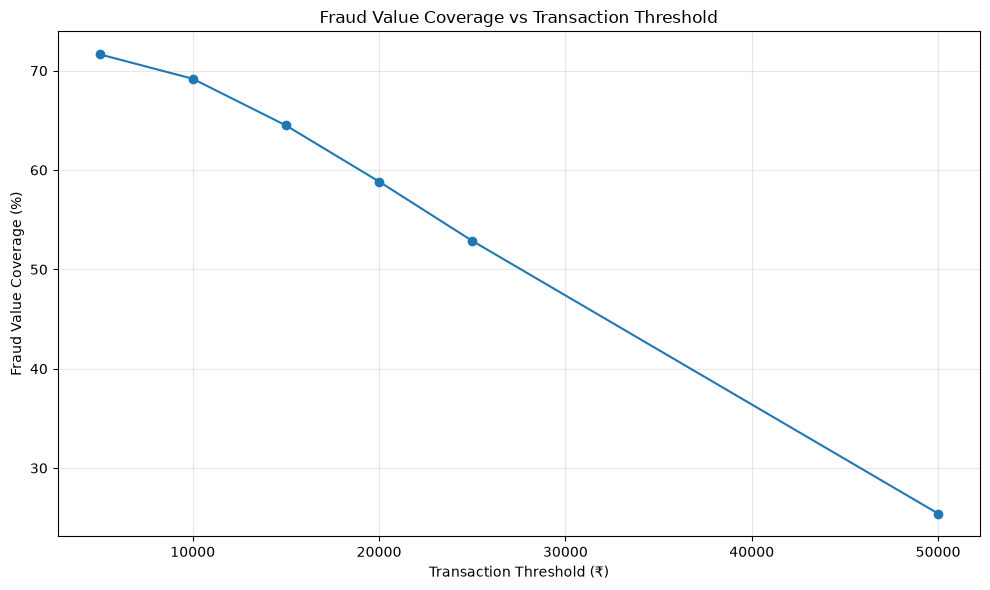

In [69]:
# Cell 51: Threshold vs fraud-value coverage

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_analysis["threshold"],
    threshold_analysis["fraud_value_coverage_pct"],
    marker="o"
)

plt.title(
    "Fraud Value Coverage vs Transaction Threshold"
)
plt.xlabel("Transaction Threshold (₹)")
plt.ylabel("Fraud Value Coverage (%)")

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

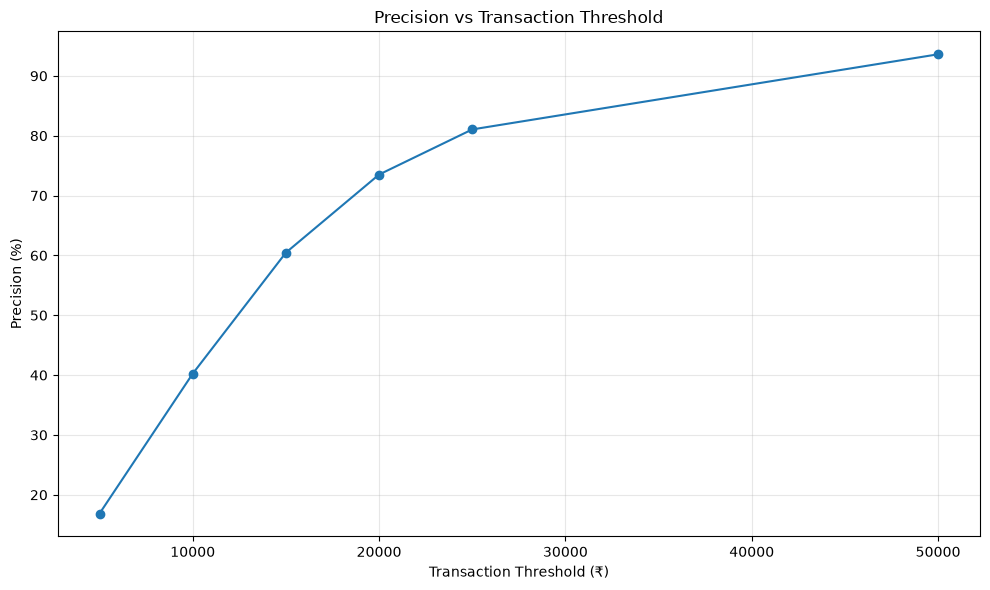

In [70]:
# Cell 52: Precision vs transaction threshold

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_analysis["threshold"],
    threshold_analysis["precision_pct"],
    marker="o"
)

plt.title(
    "Precision vs Transaction Threshold"
)
plt.xlabel("Transaction Threshold (₹)")
plt.ylabel("Precision (%)")

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [71]:
# Cell 53: Fine threshold sweep for the strongest candidate pattern

fine_thresholds = [
    10000,
    12500,
    15000,
    17500,
    20000,
    22500,
    25000,
    30000,
    40000,
    50000
]

fine_results = []

for threshold in fine_thresholds:

    mask = (
        transactions["is_ecommerce"] &
        transactions["is_high_risk_category"] &
        (transactions["amount"] >= threshold)
    )

    matched = transactions.loc[mask]

    alerts = len(matched)

    fraud_transactions = matched["is_fraud"].sum()

    fraud_value = matched.loc[
        matched["is_fraud"] == 1,
        "amount"
    ].sum()

    precision = (
        fraud_transactions / alerts * 100
        if alerts > 0 else 0
    )

    fraud_value_coverage = (
        fraud_value / total_fraud_value * 100
        if total_fraud_value > 0 else 0
    )

    legitimate_alerts = alerts - fraud_transactions

    false_positive_rate = (
        legitimate_alerts / alerts * 100
        if alerts > 0 else 0
    )

    fine_results.append({
        "threshold": threshold,
        "alerts": alerts,
        "fraud_transactions": fraud_transactions,
        "legitimate_alerts": legitimate_alerts,
        "precision_pct": precision,
        "false_positive_rate_pct": false_positive_rate,
        "fraud_value": fraud_value,
        "fraud_value_coverage_pct": fraud_value_coverage
    })

fine_threshold_analysis = pd.DataFrame(fine_results)

display(fine_threshold_analysis)

,threshold,alerts,fraud_transactions,legitimate_alerts,precision_pct,false_positive_rate_pct,fraud_value,fraud_value_coverage_pct
0,10000,4938,1987,2951,40.24,59.76,"65,862,706.81",69.19
1,12500,3528,1807,1721,51.22,48.78,"63,853,800.22",67.07
2,15000,2691,1627,1064,60.46,39.54,"61,391,754.17",64.49
3,17500,2177,1464,713,67.25,32.75,"58,750,068.30",61.71
4,20000,1793,1318,475,73.51,26.49,"56,011,958.64",58.84
5,22500,1516,1183,333,78.03,21.97,"53,143,559.23",55.82
6,25000,1314,1065,249,81.05,18.95,"50,330,951.71",52.87
7,30000,978,840,138,85.89,14.11,"44,157,536.69",46.39
8,40000,585,528,57,90.26,9.74,"33,406,649.89",35.09
9,50000,344,322,22,93.60,6.40,"24,201,410.45",25.42


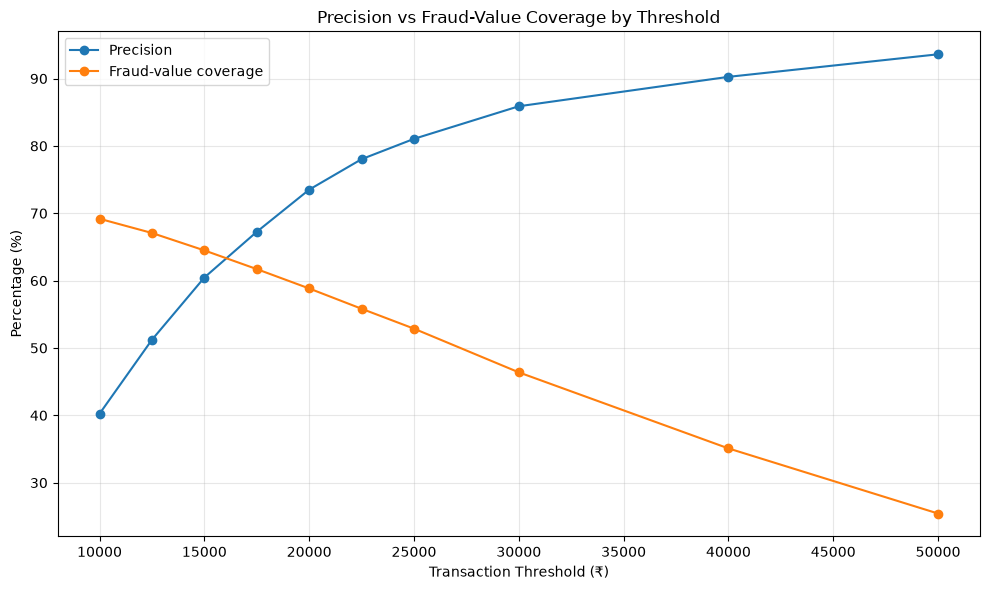

In [72]:
# Cell 54: Precision vs fraud-value coverage

plt.figure(figsize=(10, 6))

plt.plot(
    fine_threshold_analysis["threshold"],
    fine_threshold_analysis["precision_pct"],
    marker="o",
    label="Precision"
)

plt.plot(
    fine_threshold_analysis["threshold"],
    fine_threshold_analysis["fraud_value_coverage_pct"],
    marker="o",
    label="Fraud-value coverage"
)

plt.title(
    "Precision vs Fraud-Value Coverage by Threshold"
)

plt.xlabel("Transaction Threshold (₹)")
plt.ylabel("Percentage (%)")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

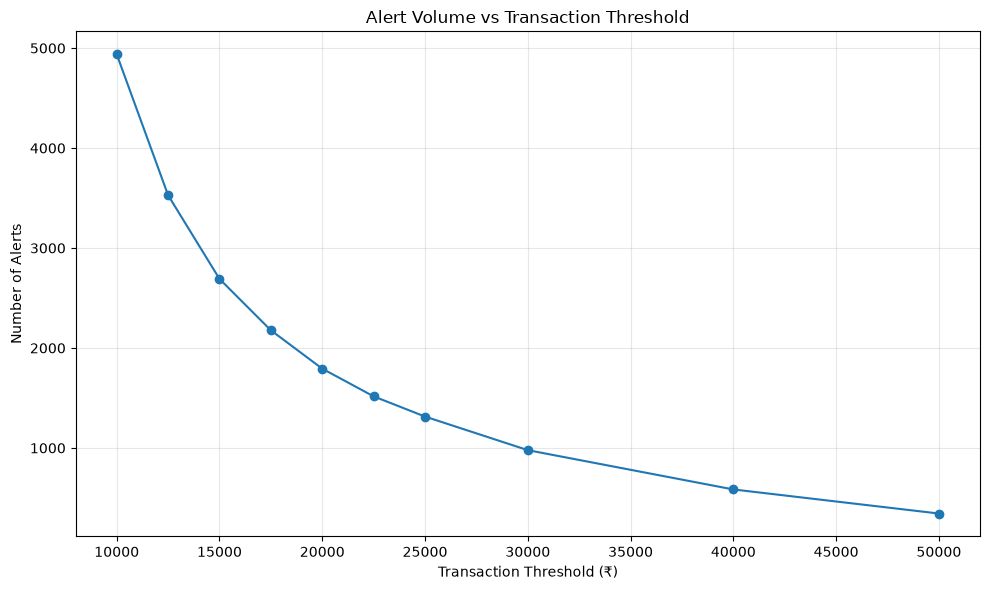

In [73]:
# Cell 55: Alert volume by threshold

plt.figure(figsize=(10, 6))

plt.plot(
    fine_threshold_analysis["threshold"],
    fine_threshold_analysis["alerts"],
    marker="o"
)

plt.title(
    "Alert Volume vs Transaction Threshold"
)

plt.xlabel("Transaction Threshold (₹)")
plt.ylabel("Number of Alerts")

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

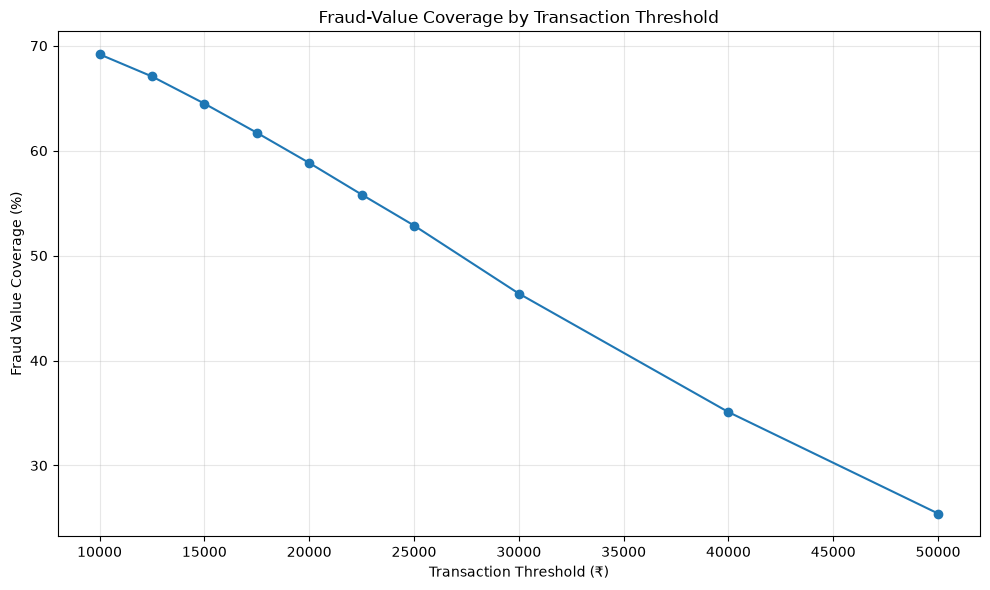

In [74]:
# Cell 56: Fraud-value coverage by threshold

plt.figure(figsize=(10, 6))

plt.plot(
    fine_threshold_analysis["threshold"],
    fine_threshold_analysis["fraud_value_coverage_pct"],
    marker="o"
)

plt.title(
    "Fraud-Value Coverage by Transaction Threshold"
)

plt.xlabel("Transaction Threshold (₹)")
plt.ylabel("Fraud Value Coverage (%)")

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

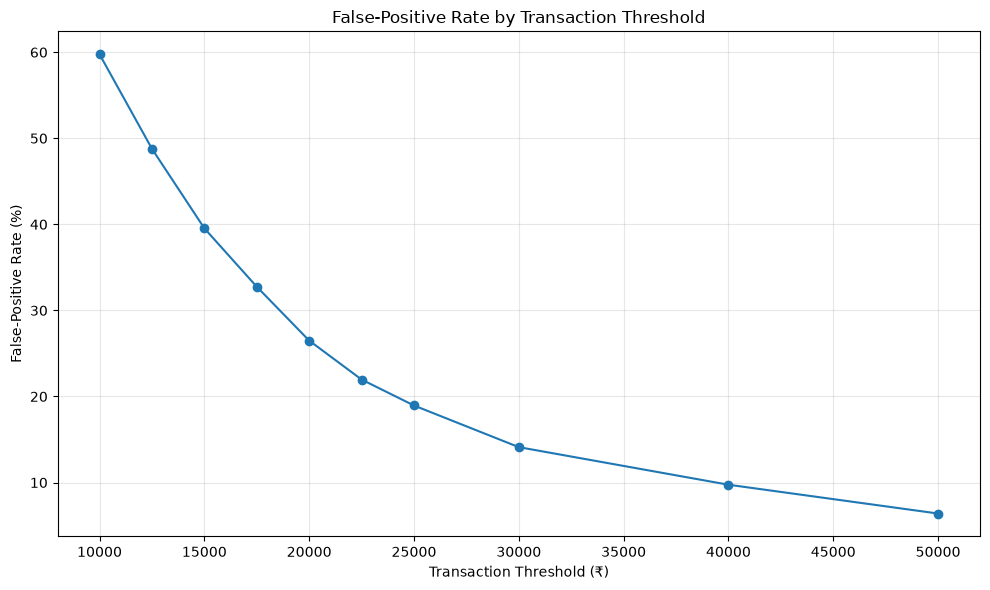

In [75]:
# Cell 57: False-positive rate by threshold

plt.figure(figsize=(10, 6))

plt.plot(
    fine_threshold_analysis["threshold"],
    fine_threshold_analysis["false_positive_rate_pct"],
    marker="o"
)

plt.title(
    "False-Positive Rate by Transaction Threshold"
)

plt.xlabel("Transaction Threshold (₹)")
plt.ylabel("False-Positive Rate (%)")

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [76]:
# Time-based train/validation split
# Development: Jan-Aug 2025
# Validation: Sep-Dec 2025

development_mask = transactions["txn_ts"] < "2025-09-01"
validation_mask = transactions["txn_ts"] >= "2025-09-01"

development = transactions.loc[development_mask].copy()
validation = transactions.loc[validation_mask].copy()

print("Development period:")
print(development["txn_ts"].min(), "to", development["txn_ts"].max())
print("Transactions:", len(development))

print("\nValidation period:")
print(validation["txn_ts"].min(), "to", validation["txn_ts"].max())
print("Transactions:", len(validation))

Development period:
2025-01-01 00:00:03 to 2025-08-31 23:59:47
Transactions: 997939

Validation period:
2025-09-01 00:00:47 to 2025-12-31 23:59:35
Transactions: 500414


In [77]:
# Threshold sweep on development period

fine_thresholds = [
    10000, 12500, 15000, 17500, 20000,
    22500, 25000, 30000, 40000, 50000
]

development_results = []

for threshold in fine_thresholds:

    mask = (
        development["is_ecommerce"]
        & development["is_high_risk_category"]
        & (development["amount"] >= threshold)
    )

    matched = development.loc[mask]

    alerts = len(matched)
    fraud_transactions = matched["is_fraud"].sum()
    legitimate_alerts = alerts - fraud_transactions

    fraud_value = matched.loc[
        matched["is_fraud"] == 1, "amount"
    ].sum()

    development_total_fraud_value = development.loc[
        development["is_fraud"] == 1, "amount"
    ].sum()

    precision = (
        fraud_transactions / alerts * 100
        if alerts > 0 else 0
    )

    false_positive_rate = (
        legitimate_alerts / alerts * 100
        if alerts > 0 else 0
    )

    fraud_value_coverage = (
        fraud_value / development_total_fraud_value * 100
        if development_total_fraud_value > 0 else 0
    )

    development_results.append({
        "threshold": threshold,
        "alerts": alerts,
        "fraud_transactions": fraud_transactions,
        "legitimate_alerts": legitimate_alerts,
        "precision_pct": precision,
        "false_positive_rate_pct": false_positive_rate,
        "fraud_value": fraud_value,
        "fraud_value_coverage_pct": fraud_value_coverage
    })

development_threshold_analysis = pd.DataFrame(development_results)

display(development_threshold_analysis)

,threshold,alerts,fraud_transactions,legitimate_alerts,precision_pct,false_positive_rate_pct,fraud_value,fraud_value_coverage_pct
0,10000,3135,1339,1796,42.71,57.29,"44,037,512.82",69.45
1,12500,2255,1203,1052,53.35,46.65,"42,524,559.16",67.06
2,15000,1731,1084,647,62.62,37.38,"40,897,148.51",64.50
3,17500,1412,976,436,69.12,30.88,"39,146,280.26",61.74
4,20000,1177,886,291,75.28,24.72,"37,461,756.66",59.08
5,22500,1003,793,210,79.06,20.94,"35,486,215.71",55.96
6,25000,868,716,152,82.49,17.51,"33,654,520.69",53.08
7,30000,651,564,87,86.64,13.36,"29,491,549.42",46.51
8,40000,386,354,32,91.71,8.29,"22,235,268.24",35.07
9,50000,230,217,13,94.35,5.65,"16,120,947.34",25.42


In [78]:
# Threshold sweep on unseen validation period

validation_results = []

for threshold in fine_thresholds:

    mask = (
        validation["is_ecommerce"]
        & validation["is_high_risk_category"]
        & (validation["amount"] >= threshold)
    )

    matched = validation.loc[mask]

    alerts = len(matched)
    fraud_transactions = matched["is_fraud"].sum()
    legitimate_alerts = alerts - fraud_transactions

    fraud_value = matched.loc[
        matched["is_fraud"] == 1, "amount"
    ].sum()

    validation_total_fraud_value = validation.loc[
        validation["is_fraud"] == 1, "amount"
    ].sum()

    precision = (
        fraud_transactions / alerts * 100
        if alerts > 0 else 0
    )

    false_positive_rate = (
        legitimate_alerts / alerts * 100
        if alerts > 0 else 0
    )

    fraud_value_coverage = (
        fraud_value / validation_total_fraud_value * 100
        if validation_total_fraud_value > 0 else 0
    )

    validation_results.append({
        "threshold": threshold,
        "alerts": alerts,
        "fraud_transactions": fraud_transactions,
        "legitimate_alerts": legitimate_alerts,
        "precision_pct": precision,
        "false_positive_rate_pct": false_positive_rate,
        "fraud_value": fraud_value,
        "fraud_value_coverage_pct": fraud_value_coverage
    })

validation_threshold_analysis = pd.DataFrame(validation_results)

display(validation_threshold_analysis)

,threshold,alerts,fraud_transactions,legitimate_alerts,precision_pct,false_positive_rate_pct,fraud_value,fraud_value_coverage_pct
0,10000,1803,648,1155,35.94,64.06,"21,825,193.99",68.66
1,12500,1273,604,669,47.45,52.55,"21,329,241.06",67.10
2,15000,960,543,417,56.56,43.44,"20,494,605.66",64.47
3,17500,765,488,277,63.79,36.21,"19,603,788.04",61.67
4,20000,616,432,184,70.13,29.87,"18,550,201.98",58.35
5,22500,513,390,123,76.02,23.98,"17,657,343.52",55.55
6,25000,446,349,97,78.25,21.75,"16,676,431.02",52.46
7,30000,327,276,51,84.40,15.60,"14,665,987.27",46.14
8,40000,199,174,25,87.44,12.56,"11,171,381.65",35.14
9,50000,114,105,9,92.11,7.89,"8,080,463.11",25.42


In [79]:
# Business assumptions for rule cost-benefit simulation

business_assumptions = {
    "review_cost_per_alert": 150,          # ₹ per alert reviewed
    "customer_friction_per_legit_alert": 100,  # ₹ estimated cost
    "fraud_prevention_rate": 0.80,         # 80% of alerted fraud value prevented
    "review_capacity_per_month": 500,      # maximum alerts reviewable per month
    "recovery_rate": 0.20                  # 20% recovered after fraud
}

assumptions_df = pd.DataFrame(
    list(business_assumptions.items()),
    columns=["assumption", "value"]
)

display(assumptions_df)

,assumption,value
0,review_cost_per_alert,150.00
1,customer_friction_per_legit_alert,100.00
2,fraud_prevention_rate,0.80
3,review_capacity_per_month,500.00
4,recovery_rate,0.20


In [80]:
# Calculate financial impact of each threshold on the validation period

review_cost = business_assumptions["review_cost_per_alert"]
friction_cost = business_assumptions["customer_friction_per_legit_alert"]
prevention_rate = business_assumptions["fraud_prevention_rate"]
recovery_rate = business_assumptions["recovery_rate"]
monthly_capacity = business_assumptions["review_capacity_per_month"]

cost_benefit_results = []

for _, row in validation_threshold_analysis.iterrows():

    threshold = row["threshold"]
    alerts = row["alerts"]
    fraud_value = row["fraud_value"]
    legitimate_alerts = row["legitimate_alerts"]

    # Estimated fraud value prevented by the rule
    prevented_fraud_value = fraud_value * prevention_rate

    # Estimated amount recovered after remaining fraud
    unrecovered_fraud_value = fraud_value * (1 - prevention_rate)
    recovery_value = unrecovered_fraud_value * recovery_rate

    # Operational costs
    alert_review_cost = alerts * review_cost
    customer_friction_cost = legitimate_alerts * friction_cost

    # Net financial benefit
    gross_benefit = prevented_fraud_value + recovery_value

    total_operational_cost = (
        alert_review_cost +
        customer_friction_cost
    )

    net_savings = gross_benefit - total_operational_cost

    # Monthly alert volume during the 4-month validation period
    avg_monthly_alerts = alerts / 4

    capacity_utilization_pct = (
        avg_monthly_alerts / monthly_capacity * 100
    )

    capacity_status = (
        "Within capacity"
        if avg_monthly_alerts <= monthly_capacity
        else "Over capacity"
    )

    cost_benefit_results.append({
        "threshold": threshold,
        "alerts": alerts,
        "fraud_value": fraud_value,
        "legitimate_alerts": legitimate_alerts,
        "prevented_fraud_value": prevented_fraud_value,
        "recovery_value": recovery_value,
        "alert_review_cost": alert_review_cost,
        "customer_friction_cost": customer_friction_cost,
        "net_savings": net_savings,
        "avg_monthly_alerts": avg_monthly_alerts,
        "capacity_utilization_pct": capacity_utilization_pct,
        "capacity_status": capacity_status
    })

cost_benefit_analysis = pd.DataFrame(cost_benefit_results)

display(cost_benefit_analysis)

,threshold,alerts,fraud_value,legitimate_alerts,prevented_fraud_value,recovery_value,alert_review_cost,customer_friction_cost,net_savings,avg_monthly_alerts,capacity_utilization_pct,capacity_status
0,"10,000.00","1,803.00","21,825,193.99","1,155.00","17,460,155.19","873,007.76","270,450.00","115,500.00","17,947,212.95",450.75,90.15,Within capacity
1,"12,500.00","1,273.00","21,329,241.06",669.00,"17,063,392.85","853,169.64","190,950.00","66,900.00","17,658,712.49",318.25,63.65,Within capacity
2,"15,000.00",960.00,"20,494,605.66",417.00,"16,395,684.53","819,784.23","144,000.00","41,700.00","17,029,768.75",240.00,48.00,Within capacity
3,"17,500.00",765.00,"19,603,788.04",277.00,"15,683,030.43","784,151.52","114,750.00","27,700.00","16,324,731.95",191.25,38.25,Within capacity
4,"20,000.00",616.00,"18,550,201.98",184.00,"14,840,161.58","742,008.08","92,400.00","18,400.00","15,471,369.66",154.00,30.80,Within capacity
5,"22,500.00",513.00,"17,657,343.52",123.00,"14,125,874.82","706,293.74","76,950.00","12,300.00","14,742,918.56",128.25,25.65,Within capacity
6,"25,000.00",446.00,"16,676,431.02",97.00,"13,341,144.82","667,057.24","66,900.00","9,700.00","13,931,602.06",111.50,22.30,Within capacity
7,"30,000.00",327.00,"14,665,987.27",51.00,"11,732,789.82","586,639.49","49,050.00","5,100.00","12,265,279.31",81.75,16.35,Within capacity
8,"40,000.00",199.00,"11,171,381.65",25.00,"8,937,105.32","446,855.27","29,850.00","2,500.00","9,351,610.59",49.75,9.95,Within capacity
9,"50,000.00",114.00,"8,080,463.11",9.00,"6,464,370.49","323,218.52","17,100.00",900.00,"6,769,589.01",28.50,5.70,Within capacity


In [81]:
# Apply a conservative operational capacity constraint

preferred_capacity_utilization = 70

capacity_constrained = cost_benefit_analysis[
    cost_benefit_analysis["capacity_utilization_pct"]
    <= preferred_capacity_utilization
].copy()

capacity_constrained = capacity_constrained.sort_values(
    "net_savings",
    ascending=False
).reset_index(drop=True)

print(
    f"Preferred maximum capacity utilization: "
    f"{preferred_capacity_utilization}%"
)

print(
    f"Preferred maximum alerts/month: "
    f"{monthly_capacity * preferred_capacity_utilization / 100:.0f}"
)

display(capacity_constrained)

Preferred maximum capacity utilization: 70%
Preferred maximum alerts/month: 350


,threshold,alerts,fraud_value,legitimate_alerts,prevented_fraud_value,recovery_value,alert_review_cost,customer_friction_cost,net_savings,avg_monthly_alerts,capacity_utilization_pct,capacity_status
0,"12,500.00","1,273.00","21,329,241.06",669.00,"17,063,392.85","853,169.64","190,950.00","66,900.00","17,658,712.49",318.25,63.65,Within capacity
1,"15,000.00",960.00,"20,494,605.66",417.00,"16,395,684.53","819,784.23","144,000.00","41,700.00","17,029,768.75",240.00,48.00,Within capacity
2,"17,500.00",765.00,"19,603,788.04",277.00,"15,683,030.43","784,151.52","114,750.00","27,700.00","16,324,731.95",191.25,38.25,Within capacity
3,"20,000.00",616.00,"18,550,201.98",184.00,"14,840,161.58","742,008.08","92,400.00","18,400.00","15,471,369.66",154.00,30.80,Within capacity
4,"22,500.00",513.00,"17,657,343.52",123.00,"14,125,874.82","706,293.74","76,950.00","12,300.00","14,742,918.56",128.25,25.65,Within capacity
5,"25,000.00",446.00,"16,676,431.02",97.00,"13,341,144.82","667,057.24","66,900.00","9,700.00","13,931,602.06",111.50,22.30,Within capacity
6,"30,000.00",327.00,"14,665,987.27",51.00,"11,732,789.82","586,639.49","49,050.00","5,100.00","12,265,279.31",81.75,16.35,Within capacity
7,"40,000.00",199.00,"11,171,381.65",25.00,"8,937,105.32","446,855.27","29,850.00","2,500.00","9,351,610.59",49.75,9.95,Within capacity
8,"50,000.00",114.00,"8,080,463.11",9.00,"6,464,370.49","323,218.52","17,100.00",900.00,"6,769,589.01",28.50,5.70,Within capacity


In [82]:
# Sensitivity analysis for candidate thresholds

candidate_thresholds = [12500, 15000, 20000, 25000, 30000]

sensitivity_assumptions = {
    "prevention_rate": [0.60, 0.70, 0.80, 0.90],
    "review_cost": [100, 150, 200, 250],
    "friction_cost": [50, 100, 150, 200]
}

sensitivity_results = []

for threshold in candidate_thresholds:

    row = validation_threshold_analysis[
        validation_threshold_analysis["threshold"] == threshold
    ].iloc[0]

    alerts = row["alerts"]
    fraud_value = row["fraud_value"]
    legitimate_alerts = row["legitimate_alerts"]

    for prevention_rate in sensitivity_assumptions["prevention_rate"]:

        prevented_fraud_value = fraud_value * prevention_rate

        unrecovered_fraud_value = (
            fraud_value * (1 - prevention_rate)
        )

        recovery_value = (
            unrecovered_fraud_value * recovery_rate
        )

        for review_cost in sensitivity_assumptions["review_cost"]:

            alert_review_cost = alerts * review_cost

            for friction_cost in sensitivity_assumptions["friction_cost"]:

                customer_friction_cost = (
                    legitimate_alerts * friction_cost
                )

                net_savings = (
                    prevented_fraud_value
                    + recovery_value
                    - alert_review_cost
                    - customer_friction_cost
                )

                sensitivity_results.append({
                    "threshold": threshold,
                    "prevention_rate": prevention_rate,
                    "review_cost": review_cost,
                    "friction_cost": friction_cost,
                    "net_savings": net_savings
                })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df.head(20))

,threshold,prevention_rate,review_cost,friction_cost,net_savings
0,12500,0.60,100,50,"14,343,133.92"
1,12500,0.60,100,100,"14,309,683.92"
2,12500,0.60,100,150,"14,276,233.92"
3,12500,0.60,100,200,"14,242,783.92"
4,12500,0.60,150,50,"14,279,483.92"
5,12500,0.60,150,100,"14,246,033.92"
6,12500,0.60,150,150,"14,212,583.92"
7,12500,0.60,150,200,"14,179,133.92"
8,12500,0.60,200,50,"14,215,833.92"
9,12500,0.60,200,100,"14,182,383.92"


In [83]:
# Summarize sensitivity results by threshold

sensitivity_summary = (
    sensitivity_df
    .groupby("threshold")["net_savings"]
    .agg(
        min_net_savings="min",
        max_net_savings="max",
        mean_net_savings="mean",
        median_net_savings="median",
        std_net_savings="std"
    )
    .reset_index()
)

# Rank thresholds by average modeled savings
sensitivity_summary = sensitivity_summary.sort_values(
    "mean_net_savings",
    ascending=False
).reset_index(drop=True)

display(sensitivity_summary)

,threshold,min_net_savings,max_net_savings,mean_net_savings,median_net_savings,std_net_savings
0,12500,"14,051,833.92","19,462,151.78","16,756,992.85","16,756,992.85","1,924,533.00"
1,15000,"13,612,931.85","18,738,187.21","16,175,559.53","16,175,559.53","1,848,525.26"
2,20000,"12,423,337.35","16,995,385.82","14,709,361.58","14,709,361.58","1,672,689.02"
3,25000,"11,209,073.09","15,292,866.54","13,250,969.82","13,250,969.82","1,503,596.65"
4,30000,"9,880,921.34","13,457,458.29","11,669,189.82","11,669,189.82","1,322,267.12"


In [84]:
# Business guardrails for final rule selection

minimum_precision = 70
maximum_capacity_utilization = 50

decision_table = validation_threshold_analysis.merge(
    cost_benefit_analysis[
        [
            "threshold",
            "net_savings",
            "avg_monthly_alerts",
            "capacity_utilization_pct"
        ]
    ],
    on="threshold",
    how="inner"
)

eligible_rules = decision_table[
    (decision_table["precision_pct"] >= minimum_precision)
    & (
        decision_table["capacity_utilization_pct"]
        <= maximum_capacity_utilization
    )
].copy()

eligible_rules = eligible_rules.sort_values(
    "net_savings",
    ascending=False
).reset_index(drop=True)

print(f"Minimum validation precision: {minimum_precision}%")
print(
    f"Maximum preferred capacity utilization: "
    f"{maximum_capacity_utilization}%"
)

print("\nEligible rules:")
display(
    eligible_rules[
        [
            "threshold",
            "alerts",
            "precision_pct",
            "false_positive_rate_pct",
            "fraud_value",
            "fraud_value_coverage_pct",
            "net_savings",
            "avg_monthly_alerts",
            "capacity_utilization_pct"
        ]
    ]
)

Minimum validation precision: 70%
Maximum preferred capacity utilization: 50%

Eligible rules:


,threshold,alerts,precision_pct,false_positive_rate_pct,fraud_value,fraud_value_coverage_pct,net_savings,avg_monthly_alerts,capacity_utilization_pct
0,20000,616,70.13,29.87,"18,550,201.98",58.35,"15,471,369.66",154.00,30.80
1,22500,513,76.02,23.98,"17,657,343.52",55.55,"14,742,918.56",128.25,25.65
2,25000,446,78.25,21.75,"16,676,431.02",52.46,"13,931,602.06",111.50,22.30
3,30000,327,84.40,15.60,"14,665,987.27",46.14,"12,265,279.31",81.75,16.35
4,40000,199,87.44,12.56,"11,171,381.65",35.14,"9,351,610.59",49.75,9.95
5,50000,114,92.11,7.89,"8,080,463.11",25.42,"6,769,589.01",28.50,5.70


In [85]:
# Final validation against hidden simulation ground truth

ground_truth = pd.read_csv(
    PROCESSED_PATH / ".." / "raw" / "sim_ground_truth.csv"
)

print("Ground truth shape:", ground_truth.shape)
print("\nColumns:")
print(ground_truth.columns.tolist())

display(ground_truth.head())

Ground truth shape: (10500, 2)

Columns:
['txn_id', 'typology']


,txn_id,typology
0,1154018,card_testing
1,483364,card_testing
2,262179,card_testing
3,878750,card_testing
4,684245,card_testing


In [86]:
# Attach hidden fraud typology ONLY for final validation

ground_truth_lookup = ground_truth.drop_duplicates(
    subset=["txn_id"]
)

validation_with_truth = validation.merge(
    ground_truth_lookup,
    on="txn_id",
    how="left"
)

# Selected production-style rule
validation_with_truth["selected_rule_alert"] = (
    validation_with_truth["is_ecommerce"]
    & validation_with_truth["is_high_risk_category"]
    & (validation_with_truth["amount"] >= 20000)
)

# Ground-truth fraud indicator
validation_with_truth["ground_truth_fraud"] = (
    validation_with_truth["typology"].notna()
).astype(int)

print("Validation transactions:", len(validation_with_truth))

print(
    "Ground-truth fraud transactions:",
    validation_with_truth["ground_truth_fraud"].sum()
)

print(
    "Rule alerts:",
    validation_with_truth["selected_rule_alert"].sum()
)

print("\nTypology distribution in validation period:")
display(
    validation_with_truth.loc[
        validation_with_truth["ground_truth_fraud"] == 1,
        "typology"
    ].value_counts()
)

Validation transactions: 500414
Ground-truth fraud transactions: 3524
Rule alerts: 616

Typology distribution in validation period:


typology
card_testing              716
account_takeover          693
cnp_high_risk_merchant    622
cross_border_spike        509
compromised_terminal      506
impossible_travel         478
Name: count, dtype: int64

In [87]:
# Final hidden-ground-truth performance of the selected ₹20K rule

tp = (
    (validation_with_truth["selected_rule_alert"] == True)
    & (validation_with_truth["ground_truth_fraud"] == 1)
).sum()

fp = (
    (validation_with_truth["selected_rule_alert"] == True)
    & (validation_with_truth["ground_truth_fraud"] == 0)
).sum()

fn = (
    (validation_with_truth["selected_rule_alert"] == False)
    & (validation_with_truth["ground_truth_fraud"] == 1)
).sum()

tn = (
    (validation_with_truth["selected_rule_alert"] == False)
    & (validation_with_truth["ground_truth_fraud"] == 0)
).sum()

ground_truth_precision = (
    tp / (tp + fp) * 100
    if (tp + fp) > 0 else 0
)

ground_truth_recall = (
    tp / (tp + fn) * 100
    if (tp + fn) > 0 else 0
)

ground_truth_fpr = (
    fp / (fp + tn) * 100
    if (fp + tn) > 0 else 0
)

ground_truth_f1 = (
    2 * (
        ground_truth_precision * ground_truth_recall
    ) / (
        ground_truth_precision + ground_truth_recall
    )
    if (ground_truth_precision + ground_truth_recall) > 0
    else 0
)

ground_truth_results = pd.DataFrame({
    "metric": [
        "True positives",
        "False positives",
        "False negatives",
        "True negatives",
        "Precision",
        "Recall",
        "False positive rate",
        "F1 score"
    ],
    "value": [
        tp,
        fp,
        fn,
        tn,
        ground_truth_precision,
        ground_truth_recall,
        ground_truth_fpr,
        ground_truth_f1
    ]
})

display(ground_truth_results)

,metric,value
0,True positives,432.00
1,False positives,184.00
2,False negatives,"3,092.00"
3,True negatives,"496,706.00"
4,Precision,70.13
5,Recall,12.26
6,False positive rate,0.04
7,F1 score,20.87


In [88]:
# Hidden-ground-truth performance by fraud typology

typology_results = []

for typology, group in validation_with_truth[
    validation_with_truth["ground_truth_fraud"] == 1
].groupby("typology"):

    actual_fraud = len(group)

    caught_by_rule = group["selected_rule_alert"].sum()

    recall = (
        caught_by_rule / actual_fraud * 100
        if actual_fraud > 0 else 0
    )

    fraud_value = group["amount"].sum()

    caught_fraud_value = group.loc[
        group["selected_rule_alert"],
        "amount"
    ].sum()

    value_coverage = (
        caught_fraud_value / fraud_value * 100
        if fraud_value > 0 else 0
    )

    typology_results.append({
        "typology": typology,
        "fraud_transactions": actual_fraud,
        "caught_by_rule": caught_by_rule,
        "transaction_recall_pct": recall,
        "total_fraud_value": fraud_value,
        "caught_fraud_value": caught_fraud_value,
        "fraud_value_coverage_pct": value_coverage
    })

typology_analysis = pd.DataFrame(
    typology_results
).sort_values(
    "fraud_value_coverage_pct",
    ascending=False
).reset_index(drop=True)

display(typology_analysis)

,typology,fraud_transactions,caught_by_rule,transaction_recall_pct,total_fraud_value,caught_fraud_value,fraud_value_coverage_pct
0,account_takeover,693,429,61.90,"21,956,097.34","18,457,704.55",84.07
1,cross_border_spike,509,1,0.20,"1,386,601.00","32,934.81",2.38
2,compromised_terminal,506,1,0.20,"2,860,627.61","30,320.07",1.06
3,impossible_travel,478,1,0.21,"3,869,297.35","29,242.55",0.76
4,card_testing,716,0,0.00,"18,493.85",0.00,0.00
5,cnp_high_risk_merchant,622,0,0.00,"1,698,068.01",0.00,0.00
